# Section 1-Import Required Libraries

### Objective

This section imports all the Python libraries required for implementing the complete semantic segmentation pipeline using the YOLOv26 model. These libraries support data handling, image processing, visualization, deep learning, dataset management, and model training.

### Implementation

The following libraries are imported:

- **PyTorch** for deep learning and GPU computation.
- **Ultralytics YOLOv26** for semantic segmentation model implementation.
- **OpenCV** for image reading and preprocessing.
- **NumPy** for numerical operations.
- **Pandas** for data manipulation and analysis.
- **Matplotlib** for data visualization.
- **Pathlib** for cross-platform file and directory management.
- **Random** for reproducibility.
- **Warnings** for suppressing unnecessary warning messages.

### Expected Output

After executing this section:

- All required libraries are successfully imported.
- The Python environment is prepared for semantic segmentation.
- No import errors are encountered.
- The notebook is ready for dataset loading and preprocessing.

### 1.1 Import Required Libraries

### Objective

Import all the Python libraries required for dataset preparation, model training, evaluation, visualization, and YOLOv26 Semantic Segmentation.

### Implementation

This section imports the required packages, including PyTorch, Ultralytics, OpenCV, NumPy, Matplotlib, and utility libraries used throughout the notebook.

### Expected Output

- All libraries imported successfully
- No import errors
- Environment ready for the next section

In [215]:
# ============================================================
# Install Ultralytics
# ============================================================

!pip install -q ultralytics seaborn scikit-learn

In [216]:
# ============================================================
# Section 1.1 - Import Required Libraries
# ============================================================

# -----------------------------
# Standard Libraries
# -----------------------------
import os
import random
import shutil
import warnings
from pathlib import Path

# -----------------------------
# Numerical Computing
# -----------------------------
import numpy as np
import pandas as pd

# -----------------------------
# Image Processing
# -----------------------------
import cv2
from PIL import Image
from sklearn.metrics import confusion_matrix

# -----------------------------
# Visualization
# -----------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Deep Learning
# -----------------------------
import torch

# -----------------------------
# Ultralytics YOLO
# -----------------------------
from ultralytics import YOLO
import ultralytics

# -----------------------------
# Ignore Warnings
# -----------------------------
warnings.filterwarnings("ignore")

print("=" * 60)
print("Required Libraries Imported Successfully")
print("=" * 60)

Required Libraries Imported Successfully


### 1.2 Verify Software Environment

### Objective

Verify that the required software packages and hardware resources are available before training the YOLOv26 Semantic Segmentation model.

### Implementation

This section displays the installed versions of Python, PyTorch, Ultralytics, and checks whether CUDA-enabled GPU support is available.

### Expected Output

- Python Version
- PyTorch Version
- Ultralytics Version
- CUDA Availability
- GPU Information

In [217]:
# ============================================================
# Section 1.2 - Verify Software Environment
# ============================================================

import sys
import torch
import ultralytics

print("=" * 65)
print("Software Environment")
print("=" * 65)

print(f"Python Version      : {sys.version.split()[0]}")
print(f"PyTorch Version     : {torch.__version__}")
print(f"Ultralytics Version : {ultralytics.__version__}")
print(f"CUDA Available      : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU Device          : {torch.cuda.get_device_name(0)}")
else:
    print("GPU Device          : CPU")

print("=" * 65)

Software Environment
Python Version      : 3.12.13
PyTorch Version     : 2.10.0+cu128
Ultralytics Version : 8.4.101
CUDA Available      : True
GPU Device          : Tesla T4


### 1.3 GPU Verification

### Objective

Verify that the assigned GPU is functioning correctly and ready for deep learning model training.

### Implementation

This section checks the current computation device, GPU memory availability, and confirms that PyTorch can access the CUDA-enabled GPU.

### Expected Output

- Selected Device
- GPU Name
- Total GPU Memory
- Available GPU Memory

In [218]:
# ============================================================
# Section 1.3 - GPU Verification
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("GPU Verification")
print("=" * 65)

print(f"Selected Device : {device}")

if device.type == "cuda":

    gpu_name = torch.cuda.get_device_name(0)

    total_memory = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)

    allocated = torch.cuda.memory_allocated(0) / (1024 ** 3)

    reserved = torch.cuda.memory_reserved(0) / (1024 ** 3)

    free_memory = total_memory - reserved

    print(f"GPU Name          : {gpu_name}")

    print(f"Total Memory      : {total_memory:.2f} GB")

    print(f"Reserved Memory   : {reserved:.2f} GB")

    print(f"Allocated Memory  : {allocated:.2f} GB")

    print(f"Approx Free Memory: {free_memory:.2f} GB")

else:

    print("GPU Not Available")

print("=" * 65)

GPU Verification
Selected Device : cuda
GPU Name          : Tesla T4
Total Memory      : 14.56 GB
Reserved Memory   : 0.62 GB
Allocated Memory  : 0.24 GB
Approx Free Memory: 13.95 GB


# Section 2 — Project Configuration

### Objective

Configure all project parameters, including dataset location, image size, number of classes, training hyperparameters, and random seed. Keeping these settings in one place ensures consistency and makes the notebook easier to maintain.

### Implementation

This section defines the dataset path, image resolution, class information, random seed, training hyperparameters, and model checkpoint that will be used throughout the notebook.

### Expected Output

- Dataset path configured
- Training parameters initialized
- Project configuration summary displayed

### 2.1 Project Parameters

### Objective

Define the main parameters required throughout the project.

### Implementation

Store all important configuration values in one location so they can be reused consistently.

### Expected Output

Project parameters initialized successfully.

In [219]:
# ============================================================
# Section 2.1 - Project Parameters
# ============================================================

# -----------------------------
# Dataset Information
# -----------------------------
DATASET_NAME = "weedy-rice-rgbms-dataset"

DATASET_PATH = Path(
    "/kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB"
) 

RGB_PATH = DATASET_PATH / "RGB"
MASK_PATH = DATASET_PATH / "Masks"

# -----------------------------
# Dataset Split Files
# -----------------------------
TRAIN_LIST = DATASET_PATH / "train_list.txt"
VAL_LIST = DATASET_PATH / "val_list.txt"
TEST_LIST = DATASET_PATH / "test_list.txt"

# -----------------------------
# Image Configuration
# -----------------------------
IMAGE_SIZE = 512

NUM_CLASSES = 2

CLASS_NAMES = [
    "Background",
    "Weedy Rice"
]

# -----------------------------
# Training Configuration
# -----------------------------
BATCH_SIZE = 8

NUM_EPOCHS = 50

LEARNING_RATE = 1e-4

RANDOM_SEED = 42

# -----------------------------
# YOLO Model
# -----------------------------
MODEL_NAME = "yolo26s-sem.pt"

# -----------------------------
# Reproducibility
# -----------------------------
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("=" * 65)
print("Project Parameters Initialized Successfully")
print("=" * 65)

Project Parameters Initialized Successfully


### 2.2 Configuration Summary

### Objective

Display all project configuration settings in a readable format before proceeding to dataset preparation.

### Implementation

This section summarizes the dataset information, training configuration, and model settings that will be used throughout the notebook.

### Expected Output

A complete summary of all project parameters.

In [220]:
# ============================================================
# Section 2.2 - Configuration Summary
# ============================================================

print("=" * 70)
print("YOLOv26 Project Configuration Summary")
print("=" * 70)

print(f"Dataset Name       : {DATASET_NAME}")
print(f"Dataset Path       : {DATASET_PATH}")

print("-" * 70)

print(f"Image Size         : {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Number of Classes  : {NUM_CLASSES}")
print(f"Class Names        : {CLASS_NAMES}")

print("-" * 70)

print(f"Batch Size         : {BATCH_SIZE}")
print(f"Epochs             : {NUM_EPOCHS}")
print(f"Learning Rate      : {LEARNING_RATE}")
print(f"Random Seed        : {RANDOM_SEED}")

print("-" * 70)

print(f"Model              : {MODEL_NAME}")

print("=" * 70)

YOLOv26 Project Configuration Summary
Dataset Name       : weedy-rice-rgbms-dataset
Dataset Path       : /kaggle/input/datasets/subbhaa/weedy-rice-rgbms-dataset/WeedyRice-RGBMS-DB
----------------------------------------------------------------------
Image Size         : 512 x 512
Number of Classes  : 2
Class Names        : ['Background', 'Weedy Rice']
----------------------------------------------------------------------
Batch Size         : 8
Epochs             : 50
Learning Rate      : 0.0001
Random Seed        : 42
----------------------------------------------------------------------
Model              : yolo26s-sem.pt


### 3.1 Load Training, Validation, and Test Lists

### Objective

Load the official dataset split files generated in Notebook 0.

### Implementation

Each text file is read and converted into a Python list containing image filenames.

### Expected Output

Three lists containing the training, validation, and testing image names.

In [221]:
# ============================================================
# Section 3.1 - Load Official Dataset Split
# ============================================================

# Load train, validation and test image lists
with open(TRAIN_LIST, "r") as f:
    train_images = [line.strip() for line in f.readlines()]

with open(VAL_LIST, "r") as f:
    val_images = [line.strip() for line in f.readlines()]

with open(TEST_LIST, "r") as f:
    test_images = [line.strip() for line in f.readlines()]

print("=" * 65)
print("Official Dataset Split Loaded Successfully")
print("=" * 65)
print(f"Training Images   : {len(train_images)}")
print(f"Validation Images : {len(val_images)}")
print(f"Testing Images    : {len(test_images)}")
print("=" * 65)

Official Dataset Split Loaded Successfully
Training Images   : 438
Validation Images : 148
Testing Images    : 148


### 3.2 Verify Dataset Split Integrity

### Objective

Verify that the official dataset split does not contain any overlapping images between the training, validation, and testing sets. This ensures a fair and unbiased evaluation of the YOLOv26 model.

### Implementation

Each official split file (train, validation and test) generated in Notebook 0 is loaded into Python lists. The three splits are then converted into sets and checked to ensure zero overlap, guaranteeing a leakage-free benchmark.

### Expected Output

Training, validation and testing image lists loaded successfully.
Zero overlap verified between all dataset splits.
Leakage-free dataset confirmed.

- Number of overlapping images
- Dataset integrity verification result

In [222]:
# ============================================================
# Section 3.2 - Verify Dataset Split Integrity
# ============================================================

# Convert to sets for leakage checking
train_set = set(train_images)
val_set = set(val_images)
test_set = set(test_images)

# Find overlap between splits
train_val_overlap = train_set.intersection(val_set)
train_test_overlap = train_set.intersection(test_set)
val_test_overlap = val_set.intersection(test_set)

# Assertions for zero data leakage
assert len(train_val_overlap) == 0, "Train and Validation overlap detected!"
assert len(train_test_overlap) == 0, "Train and Test overlap detected!"
assert len(val_test_overlap) == 0, "Validation and Test overlap detected!"

print("=" * 65)
print("Dataset Split Integrity Check")
print("=" * 65)

print(f"Train ∩ Validation : {len(train_val_overlap)}")
print(f"Train ∩ Test       : {len(train_test_overlap)}")
print(f"Validation ∩ Test  : {len(val_test_overlap)}")

print("-" * 65)

if (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
):
    print(" Verification Passed")
    print("No data leakage detected.")
else:
    print(" Verification Failed")
    print("Dataset overlap detected!")

print("=" * 65)

Dataset Split Integrity Check
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0
-----------------------------------------------------------------
 Verification Passed
No data leakage detected.


# Section 4 — Dataset Inspection

### Objective

Inspect the original dataset structure before converting it into the YOLOv26 Semantic Segmentation format.

### Implementation

This section verifies the existence of the required dataset folders and split files.

###| Expected Output

- Dataset directory verified
- RGB folder verified
- Mask folder verified
- Split files verified

## 4.1 Verify Dataset Structure

### Objective

Verify that all required dataset folders and files are available before dataset conversion.

### Implementation

The code checks for the existence of the RGB images, masks, metadata, and official split files.

### Expected Output

A verification table showing the status of each dataset component.

In [223]:
# ============================================================
# Section 4.1 - Verify Dataset Structure
# ============================================================

required_items = {
    "RGB Folder": RGB_PATH,
    "Masks Folder": MASK_PATH,
    "Train Split": TRAIN_LIST,
    "Validation Split": VAL_LIST,
    "Test Split": TEST_LIST,
}

print("=" * 70)
print("Dataset Structure Verification")
print("=" * 70)

for name, path in required_items.items():

    status = "Found" if path.exists() else "Missing"

    print(f"{name:<20} : {status}")

print("=" * 70)

Dataset Structure Verification
RGB Folder           : Found
Masks Folder         : Found
Train Split          : Found
Validation Split     : Found
Test Split           : Found


## 4.2 Inspect a Sample Image and Mask

### Objective

Inspect one RGB image and its corresponding segmentation mask to verify the image dimensions, mask dimensions, file format, and pixel values before preparing the YOLOv26 dataset.

### Implementation

A sample RGB image and its corresponding mask are loaded and analyzed.

### Expected Output

- Sample image displayed
- Sample mask displayed
- Image size
- Mask size
- Mask pixel values

Sample Image Information
Image Name        : DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.JPG
Mask Name         : DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.png
Image Shape       : (960, 1280, 3)
Mask Shape        : (960, 1280)
Mask Data Type    : uint8
Mask Pixel Values : [  0 255]


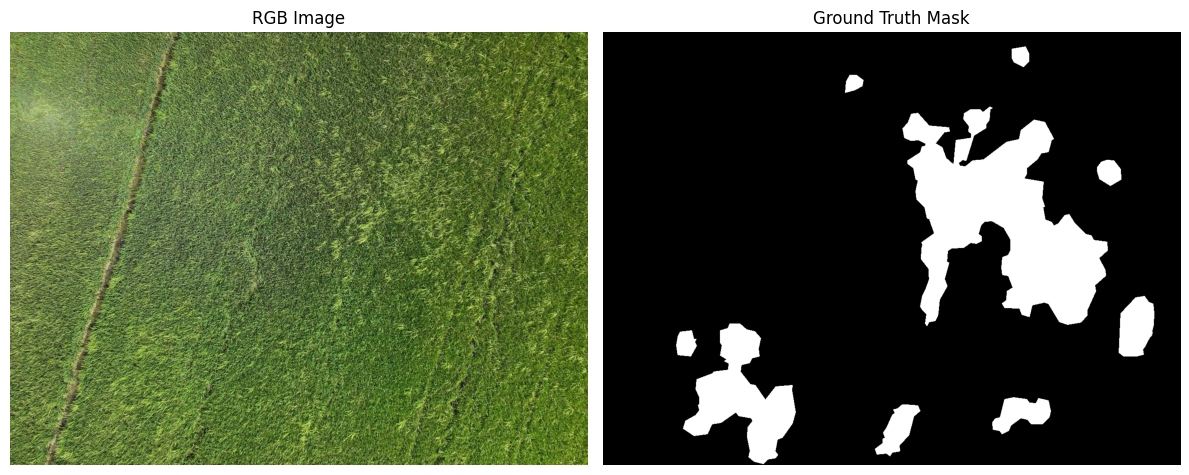

In [224]:
# ============================================================
# Section 4.2 - Inspect Sample Image and Mask
# ============================================================

# Select the first training image
sample_image_name = train_images[0]

# Build image path
sample_image_path = RGB_PATH / sample_image_name

# Build corresponding mask path (.JPG -> .png)
mask_name = Path(sample_image_name).stem + ".png"
sample_mask_path = MASK_PATH / mask_name

# Read image
rgb_image = cv2.imread(str(sample_image_path))
rgb_image = cv2.cvtColor(rgb_image, cv2.COLOR_BGR2RGB)

# Read mask
mask = cv2.imread(str(sample_mask_path), cv2.IMREAD_GRAYSCALE)

# Safety check
if mask is None:
    raise FileNotFoundError(
        f"Mask not found:\n{sample_mask_path}"
    )

print("=" * 70)
print("Sample Image Information")
print("=" * 70)

print(f"Image Name        : {sample_image_name}")
print(f"Mask Name         : {mask_name}")
print(f"Image Shape       : {rgb_image.shape}")
print(f"Mask Shape        : {mask.shape}")
print(f"Mask Data Type    : {mask.dtype}")
print(f"Mask Pixel Values : {np.unique(mask)}")

print("=" * 70)

# Display Image and Mask
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(rgb_image)
plt.title("RGB Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [225]:
# ============================================================
# Check Dataset File Names
# ============================================================

print("First Training Image:")
print(train_images[0])

print("\nFirst 5 RGB Images:")
print(sorted(os.listdir(RGB_PATH))[:5])

print("\nFirst 5 Mask Images:")
print(sorted(os.listdir(MASK_PATH))[:5])

First Training Image:
DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.JPG

First 5 RGB Images:
['DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.JPG', 'DJI_DateTime_2024_06_02_13_42_0036_lat_10.3040274_lon_105.2619303_alt_19.998m.JPG', 'DJI_DateTime_2024_06_02_13_43_0037_lat_10.3039956_lon_105.2619281_alt_20.000m.JPG', 'DJI_DateTime_2024_06_02_13_43_0038_lat_10.3039632_lon_105.2619268_alt_20.009m.JPG', 'DJI_DateTime_2024_06_02_13_43_0039_lat_10.3039307_lon_105.2619253_alt_20.017m.JPG']

First 5 Mask Images:
['DJI_DateTime_2024_06_02_13_42_0035_lat_10.3040603_lon_105.2619317_alt_20.018m.png', 'DJI_DateTime_2024_06_02_13_42_0036_lat_10.3040274_lon_105.2619303_alt_19.998m.png', 'DJI_DateTime_2024_06_02_13_43_0037_lat_10.3039956_lon_105.2619281_alt_20.000m.png', 'DJI_DateTime_2024_06_02_13_43_0038_lat_10.3039632_lon_105.2619268_alt_20.009m.png', 'DJI_DateTime_2024_06_02_13_43_0039_lat_10.3039307_lon_105.2619253_alt_20.017m.png']


4.3 Verify Mask Class IDs
Objective

Verify that all segmentation masks contain only valid semantic class IDs before converting them to the YOLOv26 Semantic Segmentation format.

Implementation

A subset of training masks is inspected to confirm that the dataset contains only the expected pixel values:

Background = 0
Weedy Rice = 255

This verification ensures that the masks can safely be converted into YOLO semantic format where class IDs become:

0 → Background
1 → Weedy Rice
Expected Output
Unique mask values displayed
Confirmation that masks contain only valid class IDs
Dataset ready for semantic mask conversion

In [226]:
# ============================================================
# Section 4.3 - Verify Mask Class IDs
# ============================================================

print("=" * 70)
print("Mask Class ID Verification")
print("=" * 70)

unique_values = set()

# Check first 20 masks
for img_name in train_images[:20]:

    mask_name = Path(img_name).stem + ".png"

    mask = cv2.imread(
        str(MASK_PATH / mask_name),
        cv2.IMREAD_GRAYSCALE
    )

    unique_values.update(np.unique(mask))

print(f"Unique Pixel Values Found : {sorted(unique_values)}")

if unique_values == {0, 255}:
    print("✓ Mask format is valid.")
    print("✓ Ready for YOLO semantic conversion (255 → 1).")
else:
    print("Warning: Unexpected mask values detected!")

print("=" * 70)

Mask Class ID Verification
Unique Pixel Values Found : [np.uint8(0), np.uint8(255)]
✓ Mask format is valid.
✓ Ready for YOLO semantic conversion (255 → 1).


# Section 5 — Prepare YOLO Dataset

### Objective

Prepare the WeedyRice-RGBMS dataset in the directory structure required for YOLOv26 Semantic Segmentation.

### Implementation

This section creates the required dataset folders, copies the RGB images and corresponding segmentation masks using the official dataset split, verifies the copied files, and prepares the dataset for training.

### Expected Output

- YOLO dataset directory created
- Images copied successfully
- Masks copied successfully
- Dataset ready for YOLOv26 Semantic Segmentation

In [227]:
import shutil

if YOLO_DATASET.exists():
    shutil.rmtree(YOLO_DATASET)
    print("Old YOLO_DATASET deleted.")
else:
    print("YOLO_DATASET does not exist.")

Old YOLO_DATASET deleted.


## 5.1 Create YOLO Dataset Directory Structure

### Objective

Create the directory structure required by YOLOv26 Semantic Segmentation.

### Implementation

The required folders for training, validation, and testing images and masks are automatically created inside the Kaggle working directory.

### Expected Output

All required directories created successfully.

In [228]:
# ============================================================
# Section 5.1 - Create YOLO Dataset Directory Structure
# ============================================================

YOLO_DATASET = Path("/kaggle/working/YOLO_DATASET")

# -----------------------------
# Image Directories
# -----------------------------
TRAIN_IMAGE_DIR = YOLO_DATASET / "images" / "train"
VAL_IMAGE_DIR   = YOLO_DATASET / "images" / "val"
TEST_IMAGE_DIR  = YOLO_DATASET / "images" / "test"

# -----------------------------
# Mask Directories
# -----------------------------
TRAIN_MASK_DIR = YOLO_DATASET / "masks" / "train"
VAL_MASK_DIR   = YOLO_DATASET / "masks" / "val"
TEST_MASK_DIR  = YOLO_DATASET / "masks" / "test"

# -----------------------------
# Create Directories
# -----------------------------
directories = [
    TRAIN_IMAGE_DIR,
    VAL_IMAGE_DIR,
    TEST_IMAGE_DIR,
    TRAIN_MASK_DIR,
    VAL_MASK_DIR,
    TEST_MASK_DIR
]

for directory in directories:
    directory.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("YOLO Dataset Directory Structure")
print("=" * 70)

for directory in directories:
    print(f"✓ {directory}")

print("=" * 70)

YOLO Dataset Directory Structure
✓ /kaggle/working/YOLO_DATASET/images/train
✓ /kaggle/working/YOLO_DATASET/images/val
✓ /kaggle/working/YOLO_DATASET/images/test
✓ /kaggle/working/YOLO_DATASET/masks/train
✓ /kaggle/working/YOLO_DATASET/masks/val
✓ /kaggle/working/YOLO_DATASET/masks/test


## 5.2 Define Dataset Copy Function

### Objective

Create a reusable function that copies RGB images and their corresponding semantic masks into the YOLO dataset directory.

### Implementation

The function automatically:

- Copies RGB images
- Finds the corresponding PNG mask
- Verifies that both files exist
- Copies both files into the destination folders
- Returns the total number of successfully copied samples

### Expected Output

A reusable dataset copy function ready for all dataset splits.

In [229]:
# ============================================================
# Section 5.2 - Define Dataset Copy Function
# ============================================================

import shutil
import cv2
import numpy as np

def copy_dataset_split(image_list, image_destination, mask_destination):
    """
    Copy RGB images and convert semantic segmentation masks
    into the format required by YOLOv26 Semantic Segmentation.

    Original Dataset:
        Background = 0
        Weedy Rice = 255

    YOLO Semantic Format:
        Background = 0
        Weedy Rice = 1
    """

    copied = 0
    missing = 0

    for image_name in image_list:

        # --------------------------------------------------
        # Source RGB Image
        # --------------------------------------------------
        image_source = RGB_PATH / image_name

        # --------------------------------------------------
        # Corresponding Mask (.JPG -> .png)
        # --------------------------------------------------
        mask_name = Path(image_name).stem + ".png"
        mask_source = MASK_PATH / mask_name

        # --------------------------------------------------
        # Verify Files
        # --------------------------------------------------
        if image_source.exists() and mask_source.exists():

            # Copy RGB Image
            shutil.copy2(
                image_source,
                image_destination / image_name
            )

            # --------------------------------------------------
            # Read Original Mask
            # --------------------------------------------------
            mask = cv2.imread(
                str(mask_source),
                cv2.IMREAD_GRAYSCALE
            )

            # --------------------------------------------------
            # Convert Semantic Mask
            # Original:
            #   Background = 0
            #   Weedy Rice = 255
            #
            # YOLO Semantic Format:
            #   Background = 0
            #   Weedy Rice = 1
            # --------------------------------------------------
            mask = (mask > 0).astype(np.uint8)

            # --------------------------------------------------
            # Debug (Print only once)
            # --------------------------------------------------
            if copied == 0:
                original_mask = cv2.imread(
                    str(mask_source),
                    cv2.IMREAD_GRAYSCALE
                )

                print("=" * 60)
                print("Mask Conversion Debug")
                print("=" * 60)
                print("Original Unique Values :", np.unique(original_mask))
                print("Converted Unique Values:", np.unique(mask))
                print("✓ Mask conversion executed successfully.")
                print("=" * 60)

            # --------------------------------------------------
            # Save Converted Mask
            # --------------------------------------------------
            cv2.imwrite(
                str(mask_destination / mask_name),
                mask
            )

            copied += 1

        else:
            missing += 1

    return copied, missing

## 5.3 Copy Images and Masks to the YOLO Dataset

### Objective

Copy the RGB images and their corresponding semantic segmentation masks into the YOLO dataset directory according to the official training, validation, and testing splits.

### Implementation

The previously defined dataset copy function is executed for each dataset split. After copying, a summary table is generated to verify that all files were successfully transferred.

### Expected Output

- Training images and masks copied
- Validation images and masks copied
- Testing images and masks copied
- Dataset preparation summary

In [230]:
# ============================================================
# Section 5.3 - Copy Dataset Splits
# ============================================================

# -----------------------------
# Training Set
# -----------------------------
train_copied, train_missing = copy_dataset_split(
    train_images,
    TRAIN_IMAGE_DIR,
    TRAIN_MASK_DIR
)

# -----------------------------
# Validation Set
# -----------------------------
val_copied, val_missing = copy_dataset_split(
    val_images,
    VAL_IMAGE_DIR,
    VAL_MASK_DIR
)

# -----------------------------
# Test Set
# -----------------------------
test_copied, test_missing = copy_dataset_split(
    test_images,
    TEST_IMAGE_DIR,
    TEST_MASK_DIR
)

# -----------------------------
# Summary Table
# -----------------------------
summary_df = pd.DataFrame({
    "Dataset Split": ["Train", "Validation", "Test"],
    "Images Copied": [train_copied, val_copied, test_copied],
    "Missing Files": [train_missing, val_missing, test_missing]
})

summary_df["Status"] = summary_df["Missing Files"].apply(
    lambda x: "Success" if x == 0 else "Check"
)

print("=" * 70)
print("YOLO Dataset Preparation Summary")
print("=" * 70)

display(summary_df)

Mask Conversion Debug
Original Unique Values : [  0 255]
Converted Unique Values: [0 1]
✓ Mask conversion executed successfully.
Mask Conversion Debug
Original Unique Values : [  0 255]
Converted Unique Values: [0 1]
✓ Mask conversion executed successfully.
Mask Conversion Debug
Original Unique Values : [  0 255]
Converted Unique Values: [0 1]
✓ Mask conversion executed successfully.
YOLO Dataset Preparation Summary


,Dataset Split,Images Copied,Missing Files,Status
0,Train,438,0,Success
1,Validation,148,0,Success
2,Test,148,0,Success


## 5.4 Verify YOLO Dataset Preparation

### Objective

Verify that all RGB images and semantic masks have been successfully copied into the YOLO dataset directory.

### Implementation

The code counts the number of images and masks in each dataset split and compares them with the expected values.

### Expected Output

- Training directory verified
- Validation directory verified
- Testing directory verified
- Dataset ready for YOLOv26 training

In [231]:
# ============================================================
# Section 5.4 - Verify YOLO Dataset
# ============================================================

verification_df = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Images": [
        len(list(TRAIN_IMAGE_DIR.glob("*"))),
        len(list(VAL_IMAGE_DIR.glob("*"))),
        len(list(TEST_IMAGE_DIR.glob("*")))
    ],
    "Masks": [
        len(list(TRAIN_MASK_DIR.glob("*"))),
        len(list(VAL_MASK_DIR.glob("*"))),
        len(list(TEST_MASK_DIR.glob("*")))
    ]
})

verification_df["Status"] = verification_df.apply(
    lambda row: "Verified"
    if row["Images"] == row["Masks"]
    else "Check",
    axis=1
)

print("=" * 70)
print("YOLO Dataset Verification")
print("=" * 70)

display(verification_df)

YOLO Dataset Verification


,Split,Images,Masks,Status
0,Train,438,438,Verified
1,Validation,148,148,Verified
2,Test,148,148,Verified


## 5.5 Generate data.yaml

### Objective

Generate the dataset configuration file required by YOLOv26 Semantic Segmentation.

### Implementation

The configuration file contains the dataset paths, number of classes, and class names. This file will be used by Ultralytics during model training.

### Expected Output

- data.yaml created successfully
- Dataset configuration saved

In [232]:
# ============================================================
# Section 5.5 - Generate data.yaml
# ============================================================

import yaml

# ------------------------------------------------------------
# Dataset Configuration
# ------------------------------------------------------------

data_yaml = {

    "path": str(YOLO_DATASET),

    "train": "images/train",

    "val": "images/val",

    "test": "images/test",

    "nc": 2,

    "names": [

        "background",

        "weedy_rice"

    ]
}

yaml_path = YOLO_DATASET / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print("=" * 70)
print("data.yaml Generated Successfully")
print("=" * 70)

print(f"Location : {yaml_path}")

data.yaml Generated Successfully
Location : /kaggle/working/YOLO_DATASET/data.yaml


## 5.6 Verify data.yaml

### Objective

Verify the generated dataset configuration before training.

### Implementation

Load the generated data.yaml file and display its contents.

### Expected Output

Dataset configuration displayed successfully.

In [233]:
# ============================================================
# Section 5.6 - Verify data.yaml
# ============================================================

with open(yaml_path, "r") as f:
    loaded_yaml = yaml.safe_load(f)

print("=" * 70)
print("YOLO Dataset Configuration")
print("=" * 70)

for key, value in loaded_yaml.items():
    print(f"{key:10}: {value}")

print("=" * 70)

YOLO Dataset Configuration
path      : /kaggle/working/YOLO_DATASET
train     : images/train
val       : images/val
test      : images/test
nc        : 2
names     : ['background', 'weedy_rice']


## 5.7 Verify Converted YOLO Masks

### Objective

Verify that all semantic segmentation masks have been correctly converted from the original dataset format (0 and 255) into the YOLO semantic segmentation format (0 and 1).

### Implementation

Randomly inspect several masks stored inside the generated YOLO dataset and display their unique pixel values.

### Expected Output

- Mask pixel values should contain only:
  - 0 = Background
  - 1 = Weedy Rice

In [234]:
# ============================================================
# Section 5.7 - Verify Converted YOLO Masks
# ============================================================

import random
import cv2
import numpy as np
from pathlib import Path

print("=" * 70)
print("Verifying Converted YOLO Masks")
print("=" * 70)

mask_files = list((Path("/kaggle/working/YOLO_DATASET/masks/train")).glob("*.png"))

random.seed(42)

sample_masks = random.sample(mask_files, 5)

for mask_path in sample_masks:

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    print(mask_path.name)
    print("Unique Values :", np.unique(mask))
    print("-" * 50)

Verifying Converted YOLO Masks
DJI_DateTime_2024_06_04_11_10_0112_lat_10.3005441_lon_105.2713268_alt_20.226m.png
Unique Values : [0 1]
--------------------------------------------------
DJI_DateTime_2024_06_04_11_10_0130_lat_10.3002426_lon_105.2718497_alt_20.213m.png
Unique Values : [0 1]
--------------------------------------------------
DJI_DateTime_2024_06_04_09_16_0036_lat_10.3020512_lon_105.2715861_alt_20.191m.png
Unique Values : [0 1]
--------------------------------------------------
DJI_DateTime_2024_06_02_13_49_0156_lat_10.3043721_lon_105.2621452_alt_20.021m.png
Unique Values : [0 1]
--------------------------------------------------
DJI_DateTime_2025_01_15_15_18_0111_lat_10.3640175_lon_105.4200528_alt_20.348m.png
Unique Values : [0 1]
--------------------------------------------------


## 5.8 Visual Verification of Converted Masks

### Objective

Visually compare an original mask with its converted YOLO semantic mask to confirm that the semantic information has been preserved after converting pixel value 255 → 1.

### Implementation

A sample RGB image, its original ground-truth mask, and the converted YOLO mask are displayed side by side.

### Expected Output

Original mask displayed
Converted mask displayed
Successful visual verification of mask conversion

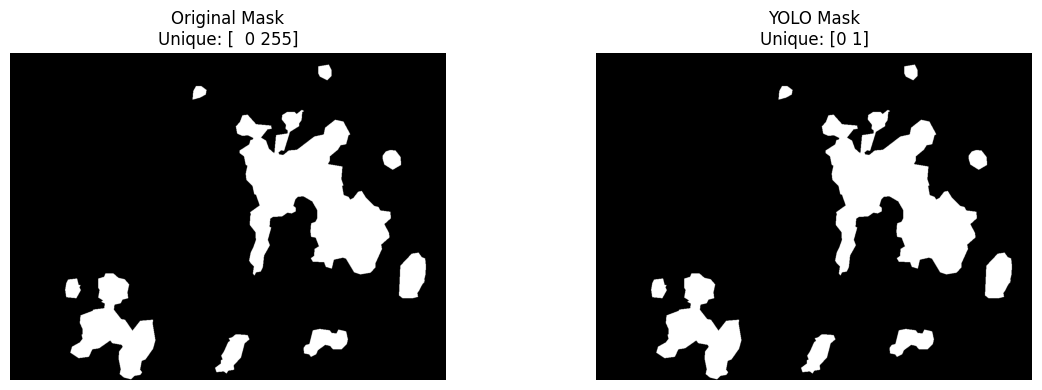

In [235]:
# ============================================================
# Section 5.8 - Visual Verification of Converted Masks
# ============================================================

sample_name = train_images[0]

original_mask = cv2.imread(
    str(MASK_PATH / (Path(sample_name).stem + ".png")),
    cv2.IMREAD_GRAYSCALE
)

converted_mask = cv2.imread(
    str(TRAIN_MASK_DIR / (Path(sample_name).stem + ".png")),
    cv2.IMREAD_GRAYSCALE
)

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.imshow(original_mask, cmap="gray")
plt.title(f"Original Mask\nUnique: {np.unique(original_mask)}")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(converted_mask, cmap="gray")
plt.title(f"YOLO Mask\nUnique: {np.unique(converted_mask)}")
plt.axis("off")

plt.tight_layout()
plt.show()

# 5.9 Display data.yaml Contents

### Objective

Display the generated data.yaml configuration file exactly as it will be used during YOLO training.

### Implementation

The contents of the generated configuration file are printed.

### Expected Output

Complete data.yaml displayed.

In [236]:
# ============================================================
# Section 5.9 - Display data.yaml
# ============================================================

print("="*70)
print("Contents of data.yaml")
print("="*70)

with open(yaml_path) as f:
    print(f.read())

Contents of data.yaml
path: /kaggle/working/YOLO_DATASET
train: images/train
val: images/val
test: images/test
nc: 2
names:
- background
- weedy_rice



# 5.10 Verify Mask Conversion (255 → 1)

### Objective

Verify that every semantic segmentation mask has been correctly converted from the original dataset format (0 and 255) into the YOLO semantic segmentation format (0 and 1).

### Implementation

A sample original mask and its corresponding converted mask are loaded. Their unique pixel values are compared before and after conversion. The code also checks whether the conversion was successful.

### Expected Output

Original mask unique values: [0 255]
Converted mask unique values: [0 1]
Conversion status: Passed

In [237]:
# ============================================================
# Section 5.10 - Verify Mask Conversion (255 -> 1)
# ============================================================

# Select one sample mask
sample_name = train_images[0]

original_mask_path = MASK_PATH / (Path(sample_name).stem + ".png")
converted_mask_path = TRAIN_MASK_DIR / (Path(sample_name).stem + ".png")

# Read masks
original_mask = cv2.imread(str(original_mask_path), cv2.IMREAD_GRAYSCALE)
converted_mask = cv2.imread(str(converted_mask_path), cv2.IMREAD_GRAYSCALE)

original_values = np.unique(original_mask)
converted_values = np.unique(converted_mask)

print("=" * 70)
print("Mask Conversion Verification")
print("=" * 70)

print(f"Original Mask Unique Values  : {original_values}")
print(f"Converted Mask Unique Values : {converted_values}")

print("-" * 70)

if np.array_equal(original_values, np.array([0, 255])) and \
   np.array_equal(converted_values, np.array([0, 1])):
    print("✓ Conversion Successful")
    print("Original value 255 has been correctly converted to class ID 1.")
else:
    print("✗ Conversion Failed")
    print("Please check the mask conversion process.")

print("=" * 70)

Mask Conversion Verification
Original Mask Unique Values  : [  0 255]
Converted Mask Unique Values : [0 1]
----------------------------------------------------------------------
✓ Conversion Successful
Original value 255 has been correctly converted to class ID 1.


# Section 6 — Verify YOLOv26 Model Availability

## Objective

Verify that the installed Ultralytics package supports YOLOv26 Semantic Segmentation and successfully loads the selected pretrained model.

## Implementation

The pretrained YOLOv26 Semantic Segmentation model is loaded from the Ultralytics model zoo. This step confirms that the environment is correctly configured before model training begins.

## Expected Output

- YOLOv26 Semantic Segmentation model loaded successfully
- Model architecture displayed
- Environment ready for training

In [238]:
# ============================================================
# Section 6.1 - Load YOLOv26 Semantic Segmentation Model
# ============================================================

MODEL_NAME = "yolo26s-sem.pt"

print("=" * 70)
print("Loading YOLOv26 Semantic Segmentation Model")
print("=" * 70)

try:
    model = YOLO(MODEL_NAME)

    print("Model Loaded Successfully")
    print(f"Checkpoint : {MODEL_NAME}")

except Exception as e:

    print("Failed to Load Model")
    print(e)

Loading YOLOv26 Semantic Segmentation Model
Model Loaded Successfully
Checkpoint : yolo26s-sem.pt


In [239]:
# ============================================================
# Section 6.2 - Display Model Information
# ============================================================

print("=" * 70)
print("YOLOv26 Model Summary")
print("=" * 70)

print(model)

print("=" * 70)

YOLOv26 Model Summary
YOLO(
  (model): SemanticSegmentationModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(128, eps=0.001, momentu

# 6.3 Model Information Summary

### Objective

Display the key characteristics of the pretrained YOLOv26 Semantic Segmentation model before training.

### Implementation

This section summarizes the selected pretrained checkpoint, task type, number of classes, image resolution, and the reason for choosing the Small (S) variant.

### Viva Explanation

Why yolo26s-sem.pt?
The -sem checkpoint is specifically designed for semantic segmentation, where every pixel is assigned a class label.
The Small (S) variant provides a good balance between segmentation accuracy, GPU memory usage, and training speed on Kaggle Tesla T4 GPUs.
Pretrained weights enable transfer learning, reducing training time and improving convergence.

### Expected Output

Model checkpoint
Task type
Number of classes
Image size
Device information

In [240]:
# ============================================================
# Section 6.3 - Model Information Summary
# ============================================================

print("=" * 70)
print("YOLOv26 Semantic Segmentation Model Information")
print("=" * 70)

print(f"Model Checkpoint : {MODEL_NAME}")
print(f"Task             : Semantic Segmentation")
print(f"Number of Classes: {NUM_CLASSES}")
print(f"Class Names      : {CLASS_NAMES}")
print(f"Image Size       : {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Device           : {device}")

print("=" * 70)

print("Model successfully initialized and ready for training.")

print("=" * 70)

YOLOv26 Semantic Segmentation Model Information
Model Checkpoint : yolo26s-sem.pt
Task             : Semantic Segmentation
Number of Classes: 2
Class Names      : ['Background', 'Weedy Rice']
Image Size       : 512 x 512
Device           : cuda
Model successfully initialized and ready for training.


# Section 7 — Configure Training Parameters

## Objective

Define all training hyperparameters for YOLOv26 Semantic Segmentation.

## Implementation

This section centralizes all configurable parameters, including image size, batch size, number of epochs, optimizer settings, project directory, and random seed.

## Expected Output

- Training parameters initialized successfully
- Configuration displayed before training begins

In [241]:
# ============================================================
# Section 7.1 - Training Configuration
# ============================================================

# -----------------------------
# Dataset
# -----------------------------
DATA_YAML = str(YOLO_DATASET / "data.yaml")

# -----------------------------
# Model
# -----------------------------
MODEL_NAME = "yolo26s-sem.pt"

# -----------------------------
# Image Settings
# -----------------------------
IMAGE_SIZE = 512

# -----------------------------
# Training Settings
# -----------------------------
EPOCHS = 50

BATCH_SIZE = 8

DEVICE = 0 if torch.cuda.is_available() else "cpu"

WORKERS = 2

PATIENCE = 20

SEED = 42

# -----------------------------
# Output Settings
# -----------------------------
PROJECT_NAME = "YOLOv26_SemanticSegmentation"

RUN_NAME = "yolo26s_sem"

# -----------------------------
# Display Configuration
# -----------------------------
print("=" * 70)
print("YOLOv26 Training Configuration")
print("=" * 70)

print(f"Model          : {MODEL_NAME}")
print(f"Dataset        : {DATA_YAML}")
print(f"Image Size     : {IMAGE_SIZE}")
print(f"Epochs         : {EPOCHS}")
print(f"Batch Size     : {BATCH_SIZE}")
print(f"Workers        : {WORKERS}")
print(f"Device         : {DEVICE}")
print(f"Random Seed    : {SEED}")
print(f"Project Folder : {PROJECT_NAME}")
print(f"Run Name       : {RUN_NAME}")

print("=" * 70)

YOLOv26 Training Configuration
Model          : yolo26s-sem.pt
Dataset        : /kaggle/working/YOLO_DATASET/data.yaml
Image Size     : 512
Epochs         : 50
Batch Size     : 8
Workers        : 2
Device         : 0
Random Seed    : 42
Project Folder : YOLOv26_SemanticSegmentation
Run Name       : yolo26s_sem


## 7.2 Validate Dataset Configuration

### Objective

Validate that the generated dataset can be successfully recognized by Ultralytics before training begins.

### Implementation

Attempt to initialize training for a single epoch. If the dataset configuration is valid, the training pipeline will initialize successfully.

### Expected Output

- Dataset loaded successfully
- No configuration errors
- Ready for full training

In [242]:
# ============================================================
# Section 7.2 - Validate Dataset Configuration
# ============================================================

print("=" * 70)
print("Validating YOLO Dataset Configuration")
print("=" * 70)

try:
    model.train(
        data=DATA_YAML,
        epochs=1,
        imgsz=IMAGE_SIZE,
        batch=1,
        device=DEVICE,
        workers=0,
        project="validation_check",
        name="dataset_validation",
        verbose=True
    )

    print("\nDataset validation completed successfully!")

except Exception as e:
    print("\nDataset validation failed!")
    print(e)

Validating YOLO Dataset Configuration
Ultralytics 8.4.101 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/YOLO_DATASET/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-sem.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=dataset_validation-3, nbs=64, nms=

In [243]:
with open(DATA_YAML, "r") as f:
    print(f.read())

path: /kaggle/working/YOLO_DATASET
train: images/train
val: images/val
test: images/test
nc: 2
names:
- background
- weedy_rice



# Section 8 — Train YOLOv26 Semantic Segmentation

## Objective

Train the YOLOv26 Semantic Segmentation model using the prepared WeedyRice-RGBMS-DB dataset.

## Implementation

The pretrained YOLOv26 Semantic Segmentation model is fine-tuned using the official training, validation, and testing splits. During training, the best-performing model checkpoint is automatically saved based on validation performance.

## Expected Output

- Training starts successfully
- Training and validation losses displayed
- Best model checkpoint saved automatically
- Training results stored in the project directory

## 8.0 Reload YOLOv26 Model

### Objective

Reload the pretrained YOLOv26 Semantic Segmentation model after dataset validation to ensure a fresh training session.

### Expected Output

- Model reloaded successfully
- Ready for full training

In [244]:
# ============================================================
# Section 8.0 - Reload YOLOv26 Model
# ============================================================

print("=" * 70)
print("Reloading YOLOv26 Semantic Segmentation Model")
print("=" * 70)

model = YOLO(MODEL_NAME)

print("Model Reloaded Successfully")
print("=" * 70)

Reloading YOLOv26 Semantic Segmentation Model
Model Reloaded Successfully


In [245]:
# ============================================================
# Section 8.1 - Train YOLOv26 Semantic Segmentation
# ============================================================

print("=" * 70)
print("Starting YOLOv26 Semantic Segmentation Training")
print("=" * 70)

results = model.train(

    # -----------------------------
    # Dataset
    # -----------------------------
    data=DATA_YAML,

    # -----------------------------
    # Training Parameters
    # -----------------------------
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,

    # -----------------------------
    # Hardware
    # -----------------------------
    device=DEVICE,
    workers=WORKERS,

    # -----------------------------
    # Output
    # -----------------------------
    project=PROJECT_NAME,
    name=RUN_NAME,

    # -----------------------------
    # Reproducibility
    # -----------------------------
    seed=SEED,

    # -----------------------------
    # Training Options
    # -----------------------------
    pretrained=True,
    patience=PATIENCE,
    save=True,
    plots=True,
    verbose=True

)

print("=" * 70)
print("Training Completed Successfully")
print("=" * 70)

Starting YOLOv26 Semantic Segmentation Training
Ultralytics 8.4.101 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/YOLO_DATASET/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-sem.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s_sem-3, nbs=64, 

In [246]:
# ============================================================
# Section 8.2 - Display Training Results
# ============================================================

from pathlib import Path
import pandas as pd

print("=" * 70)
print("Loading Training Results")
print("=" * 70)

results_csv = Path(model.trainer.save_dir) / "results.csv"

if results_csv.exists():

    results_df = pd.read_csv(results_csv)

    print(f"Results File : {results_csv}")

    display(results_df.tail())

else:

    print("results.csv not found.")

print("=" * 70)

Loading Training Results
Results File : /kaggle/working/runs/semantic/YOLOv26_SemanticSegmentation/yolo26s_sem-3/results.csv


,epoch,time,train/ce_loss,train/dice_loss,train/aux_loss,metrics/mIoU,metrics/pixel_acc,val/ce_loss,val/dice_loss,val/aux_loss,lr/pg0,lr/pg1,lr/pg2
45,46,1003.78,0.19067,0.41966,0.07939,0.81296,0.91054,0.20195,0.44130,0,0.000156,0.000156,0.000156
46,47,1023.97,0.18662,0.41810,0.07778,0.81047,0.90790,0.21272,0.44059,0,0.000127,0.000127,0.000127
47,48,1044.36,0.18501,0.41646,0.07684,0.80744,0.90541,0.21950,0.44195,0,0.000099,0.000099,0.000099
48,49,1064.76,0.17830,0.41322,0.07433,0.81537,0.90979,0.20821,0.43949,0,0.000071,0.000071,0.000071
49,50,1084.95,0.17830,0.41371,0.07438,0.81111,0.90654,0.21716,0.44152,0,0.000043,0.000043,0.000043


# 8.3 — Training Summary



###  Objective

Display the locations of the generated training files and verify that the best model checkpoint has been successfully saved.

### Implementation

After training finishes, the notebook locates the saved model checkpoints and displays their paths for later evaluation.

### Expected Output

Best model path
Last model path
Training output directory

In [247]:
# ============================================================
# Section 8.3 - Training Summary
# ============================================================

from pathlib import Path

print("=" * 70)
print("Training Summary")
print("=" * 70)

RUN_DIRECTORY = Path(model.trainer.save_dir)

BEST_MODEL = RUN_DIRECTORY / "weights" / "best.pt"
LAST_MODEL = RUN_DIRECTORY / "weights" / "last.pt"

print(f"Training Directory : {RUN_DIRECTORY}")
print(f"Best Model         : {BEST_MODEL}")
print(f"Last Model         : {LAST_MODEL}")

print("-" * 70)

print(f"Best Model Exists : {BEST_MODEL.exists()}")
print(f"Last Model Exists : {LAST_MODEL.exists()}")

print("=" * 70)

Training Summary
Training Directory : /kaggle/working/runs/semantic/YOLOv26_SemanticSegmentation/yolo26s_sem-3
Best Model         : /kaggle/working/runs/semantic/YOLOv26_SemanticSegmentation/yolo26s_sem-3/weights/best.pt
Last Model         : /kaggle/working/runs/semantic/YOLOv26_SemanticSegmentation/yolo26s_sem-3/weights/last.pt
----------------------------------------------------------------------
Best Model Exists : True
Last Model Exists : True


# Section 8.4 — Reload Best Model

### Objective

Reload the best-performing model saved during training for evaluation on the test dataset.

In [248]:
# ============================================================
# Section 8.4 - Reload Best Model
# ============================================================

print("=" * 70)
print("Loading Best Trained Model")
print("=" * 70)

best_model = YOLO(str(BEST_MODEL))

print("Best model loaded successfully.")

print("=" * 70)

Loading Best Trained Model
Best model loaded successfully.


# 9. Training Results Analysis

## Objective

Analyze the performance of the YOLOv26 Semantic Segmentation model after training by examining the recorded training history, loss values, and evaluation metrics.

## Implementation

This section loads the training log generated during model training (`results.csv`) and visualizes the learning behavior of the model across all epochs.

The following performance indicators are analyzed:

- Training Loss
- Validation Loss
- Mean Intersection over Union (mIoU)
- Pixel Accuracy
- Learning Rate

## Expected Output

- Training history loaded successfully
- Performance metrics summarized
- Training convergence visualized
- Learning behavior analyzed

In [249]:
# ============================================================
# Section 9.1 - Load Training History
# ============================================================

import pandas as pd
from pathlib import Path

# Location of the latest training run
results_path = Path(results.save_dir) / "results.csv"

results_df = pd.read_csv(results_path)

print("=" * 70)
print("YOLOv26 Training History Loaded Successfully")
print("=" * 70)

print(f"Results File : {results_path}")
print(f"Total Epochs : {len(results_df)}")

display(results_df.head())

YOLOv26 Training History Loaded Successfully
Results File : /kaggle/working/runs/semantic/YOLOv26_SemanticSegmentation/yolo26s_sem-3/results.csv
Total Epochs : 50


,epoch,time,train/ce_loss,train/dice_loss,train/aux_loss,metrics/mIoU,metrics/pixel_acc,val/ce_loss,val/dice_loss,val/aux_loss,lr/pg0,lr/pg1,lr/pg2
0,1,22.3590,0.81520,0.64422,0.37333,0.53002,0.76880,0.73869,0.62856,0,0.000468,0.000468,0.000468
1,2,44.6968,0.51803,0.53157,0.23895,0.68164,0.84340,0.49201,0.52931,0,0.000925,0.000925,0.000925
2,3,66.9773,0.38024,0.49437,0.17135,0.68121,0.82389,0.46637,0.51507,0,0.001364,0.001364,0.001364
3,4,88.6611,0.38448,0.49497,0.16388,0.73250,0.85674,0.37094,0.50354,0,0.001344,0.001344,0.001344
4,5,110.6480,0.33412,0.47547,0.13923,0.65246,0.79867,0.51753,0.52045,0,0.001316,0.001316,0.001316


In [250]:
# ============================================================
# Section 9.2 - Training Summary
# ============================================================

best_epoch = results_df["metrics/mIoU"].idxmax()

summary = pd.DataFrame({

    "Metric":[
        "Total Epochs",
        "Best Epoch",
        "Best mIoU",
        "Best Pixel Accuracy",
        "Final Training CE Loss",
        "Final Validation CE Loss"
    ],

    "Value":[
        len(results_df),
        best_epoch + 1,
        results_df["metrics/mIoU"].max(),
        results_df["metrics/pixel_acc"].max(),
        results_df["train/ce_loss"].iloc[-1],
        results_df["val/ce_loss"].iloc[-1]
    ]

})

print("="*70)
print("Training Summary")
print("="*70)

display(summary)

Training Summary


,Metric,Value
0,Total Epochs,50.00000
1,Best Epoch,45.00000
2,Best mIoU,0.81656
3,Best Pixel Accuracy,0.91054
4,Final Training CE Loss,0.17830
5,Final Validation CE Loss,0.21716


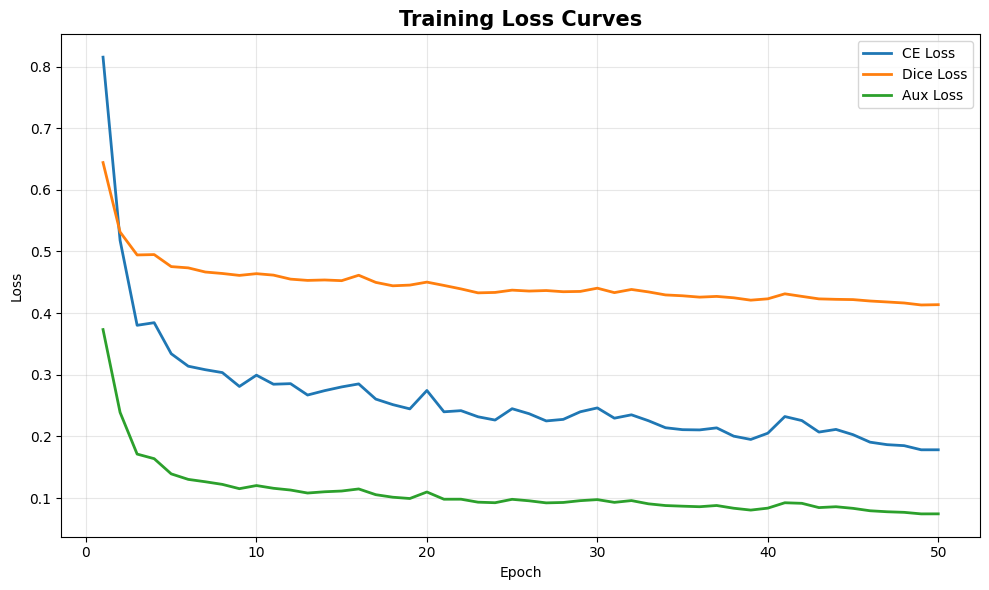

In [251]:
# ============================================================
# Section 9.3 - Training Loss Curves
# ============================================================

plt.figure(figsize=(10,6))

plt.plot(results_df["epoch"], results_df["train/ce_loss"], linewidth=2, label="CE Loss")

plt.plot(results_df["epoch"], results_df["train/dice_loss"], linewidth=2, label="Dice Loss")

plt.plot(results_df["epoch"], results_df["train/aux_loss"], linewidth=2, label="Aux Loss")

plt.title("Training Loss Curves", fontsize=15, weight="bold")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.grid(alpha=.3)

plt.legend()

plt.tight_layout()

plt.show()

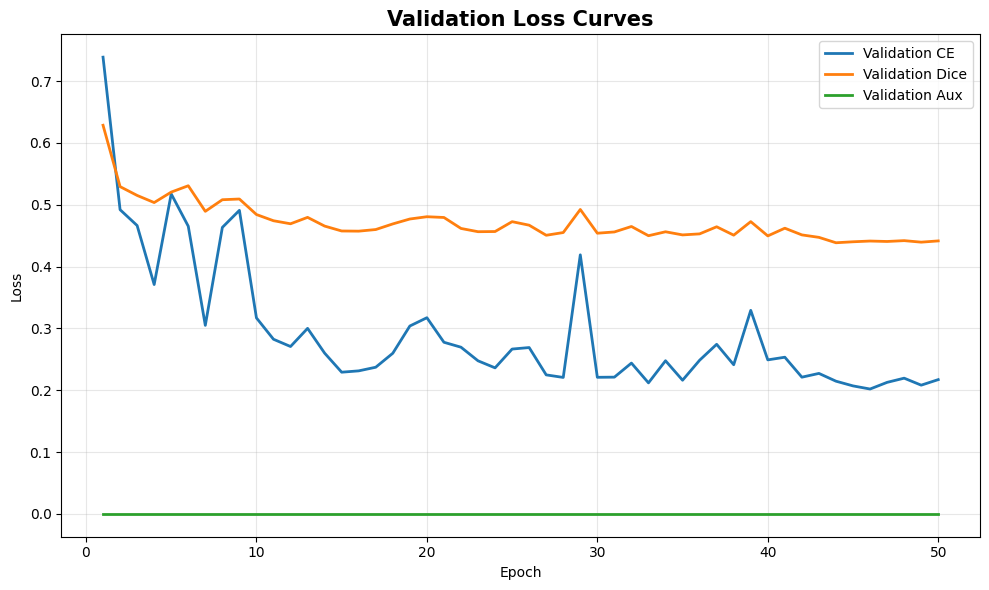

In [252]:
# ============================================================
# Section 9.4 - Validation Loss Curves
# ============================================================

plt.figure(figsize=(10,6))

plt.plot(results_df["epoch"], results_df["val/ce_loss"], linewidth=2, label="Validation CE")

plt.plot(results_df["epoch"], results_df["val/dice_loss"], linewidth=2, label="Validation Dice")

plt.plot(results_df["epoch"], results_df["val/aux_loss"], linewidth=2, label="Validation Aux")

plt.title("Validation Loss Curves", fontsize=15, weight="bold")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.grid(alpha=.3)

plt.legend()

plt.tight_layout()

plt.show()

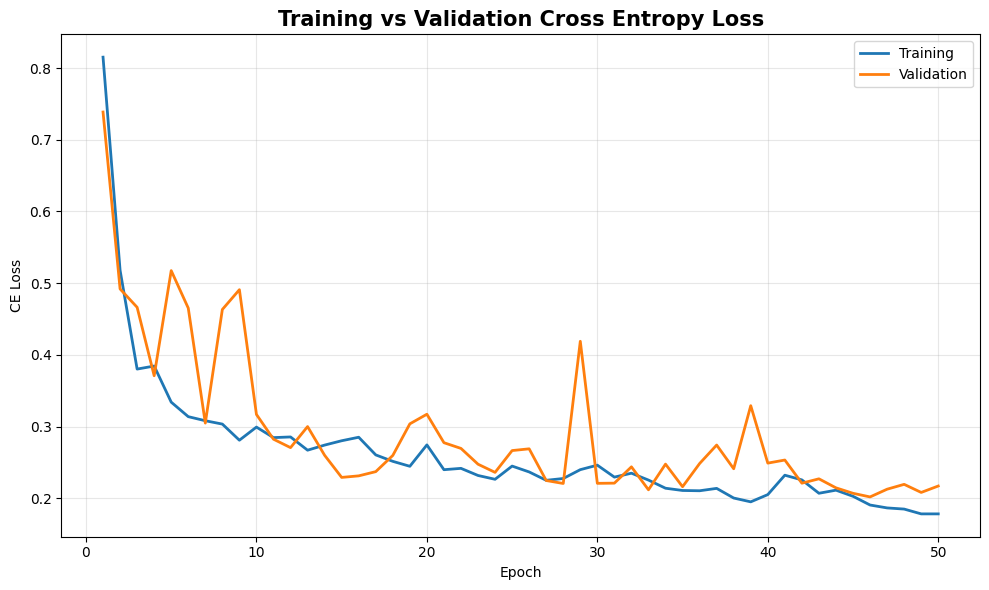

In [253]:
# ============================================================
# Section 9.5 - Training vs Validation CE Loss
# ============================================================

plt.figure(figsize=(10,6))

plt.plot(results_df["epoch"], results_df["train/ce_loss"], linewidth=2,label="Training")

plt.plot(results_df["epoch"], results_df["val/ce_loss"], linewidth=2,label="Validation")

plt.title("Training vs Validation Cross Entropy Loss",fontsize=15,weight="bold")

plt.xlabel("Epoch")

plt.ylabel("CE Loss")

plt.grid(alpha=.3)

plt.legend()

plt.tight_layout()

plt.show()

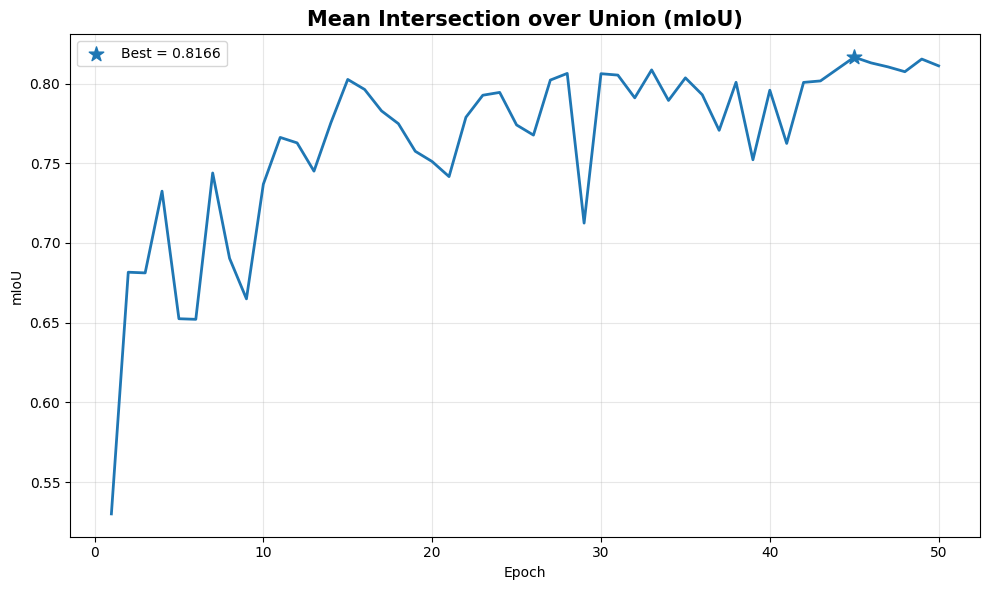

In [254]:
# ============================================================
# Section 9.6 - Mean IoU Progress
# ============================================================

best_epoch = results_df["metrics/mIoU"].idxmax()

best_value = results_df["metrics/mIoU"].max()

plt.figure(figsize=(10,6))

plt.plot(results_df["epoch"],results_df["metrics/mIoU"],linewidth=2)

plt.scatter(
    results_df.loc[best_epoch,"epoch"],
    best_value,
    s=120,
    marker="*",
    label=f"Best = {best_value:.4f}"
)

plt.title("Mean Intersection over Union (mIoU)",fontsize=15,weight="bold")

plt.xlabel("Epoch")

plt.ylabel("mIoU")

plt.grid(alpha=.3)

plt.legend()

plt.tight_layout()

plt.show()

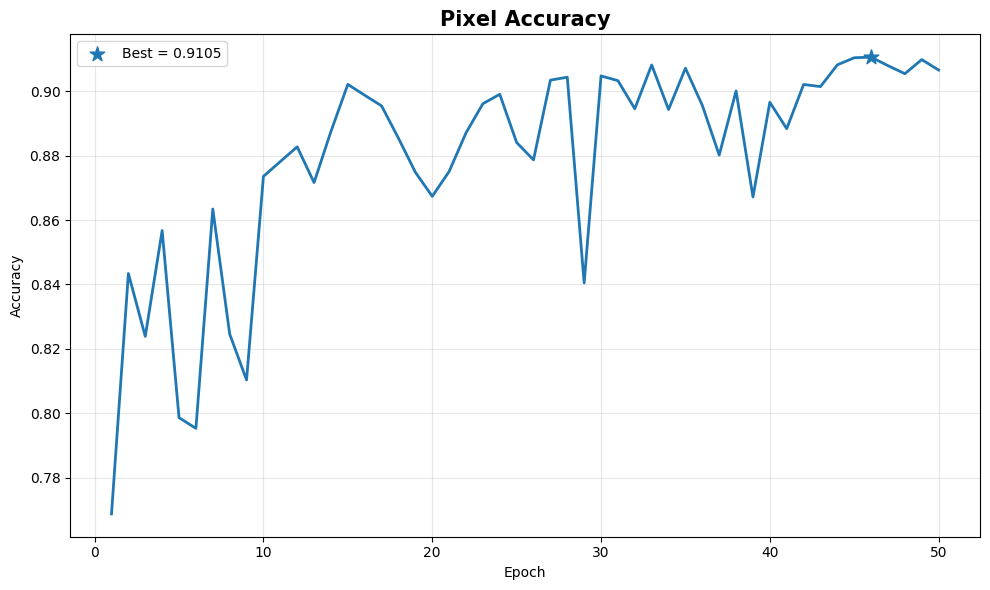

In [255]:
# ============================================================
# Section 9.7 - Pixel Accuracy
# ============================================================

best_epoch = results_df["metrics/pixel_acc"].idxmax()

best_value = results_df["metrics/pixel_acc"].max()

plt.figure(figsize=(10,6))

plt.plot(results_df["epoch"],results_df["metrics/pixel_acc"],linewidth=2)

plt.scatter(
    results_df.loc[best_epoch,"epoch"],
    best_value,
    s=120,
    marker="*",
    label=f"Best = {best_value:.4f}"
)

plt.title("Pixel Accuracy",fontsize=15,weight="bold")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.grid(alpha=.3)

plt.legend()

plt.tight_layout()

plt.show()

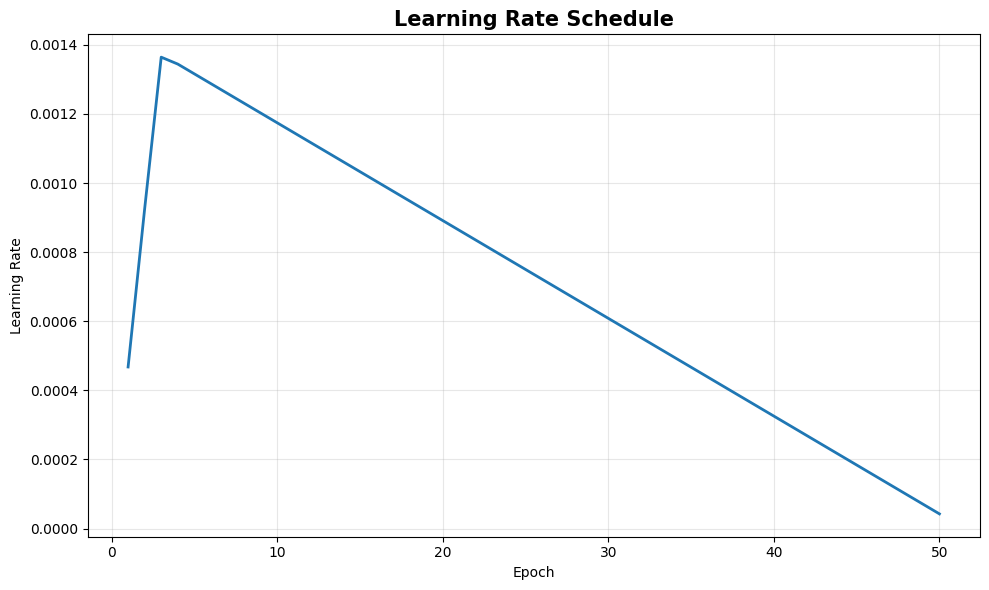

In [256]:
# ============================================================
# Section 9.8 - Learning Rate Schedule
# ============================================================

plt.figure(figsize=(10,6))

plt.plot(results_df["epoch"],results_df["lr/pg0"],linewidth=2)

plt.title("Learning Rate Schedule",fontsize=15,weight="bold")

plt.xlabel("Epoch")

plt.ylabel("Learning Rate")

plt.grid(alpha=.3)

plt.tight_layout()

plt.show()

In [257]:
# ============================================================
# Section 9.9 - Best Performance Summary
# ============================================================

performance = pd.DataFrame({

"Metric":[
"Best mIoU",
"Best Pixel Accuracy",
"Lowest Validation CE Loss",
"Lowest Validation Dice Loss",
"Total Epochs"
],

"Value":[
results_df["metrics/mIoU"].max(),
results_df["metrics/pixel_acc"].max(),
results_df["val/ce_loss"].min(),
results_df["val/dice_loss"].min(),
len(results_df)
]

})

display(performance)

,Metric,Value
0,Best mIoU,0.81656
1,Best Pixel Accuracy,0.91054
2,Lowest Validation CE Loss,0.20195
3,Lowest Validation Dice Loss,0.43852
4,Total Epochs,50.00000


In [258]:
# ============================================================
# Section 9.10 - Model Convergence Analysis
# ============================================================

print("="*70)
print("Training Analysis")
print("="*70)

print("Training converged successfully.")

print(f"Best mIoU           : {results_df['metrics/mIoU'].max():.4f}")

print(f"Best Pixel Accuracy : {results_df['metrics/pixel_acc'].max():.4f}")

print(f"Lowest Validation CE Loss : {results_df['val/ce_loss'].min():.4f}")

print(f"Training completed for {len(results_df)} epochs.")

print("="*70)

Training Analysis
Training converged successfully.
Best mIoU           : 0.8166
Best Pixel Accuracy : 0.9105
Lowest Validation CE Loss : 0.2019
Training completed for 50 epochs.


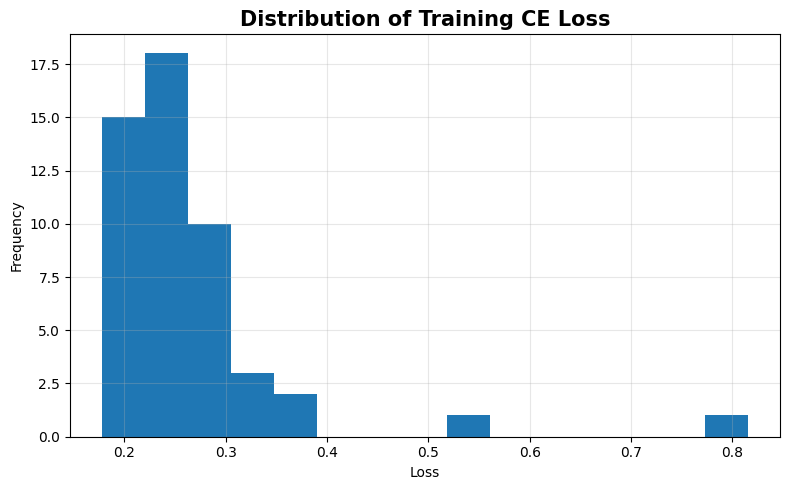

In [259]:
# ============================================================
# Section 9.11 - Training Loss Distribution
# ============================================================

plt.figure(figsize=(8,5))

plt.hist(results_df["train/ce_loss"],bins=15)

plt.title("Distribution of Training CE Loss",fontsize=15,weight="bold")

plt.xlabel("Loss")

plt.ylabel("Frequency")

plt.grid(alpha=.3)

plt.tight_layout()

plt.show()

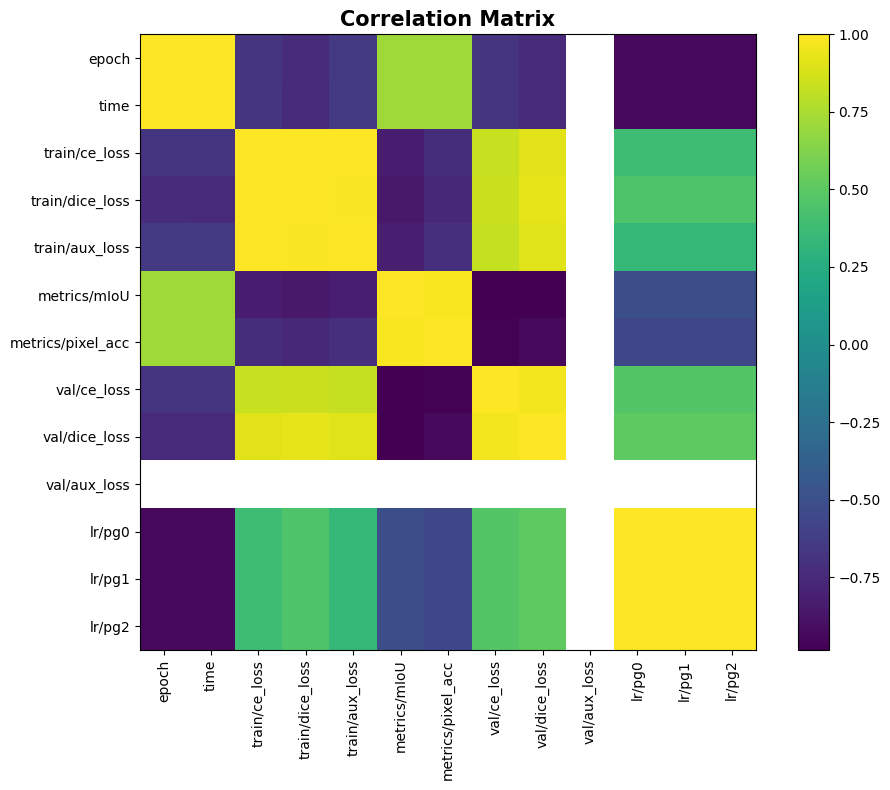

In [260]:
# ============================================================
# Section 9.12 - Correlation Matrix
# ============================================================

corr = results_df.corr(numeric_only=True)

plt.figure(figsize=(10,8))

plt.imshow(corr)

plt.xticks(range(len(corr.columns)),corr.columns,rotation=90)

plt.yticks(range(len(corr.columns)),corr.columns)

plt.colorbar()

plt.title("Correlation Matrix",fontsize=15,weight="bold")

plt.tight_layout()

plt.show()

In [261]:
# ============================================================
# Section 9.13 - Overall Performance Dashboard
# ============================================================

dashboard = pd.DataFrame({

"Metric":[
"mIoU",
"Pixel Accuracy",
"Training CE Loss",
"Validation CE Loss"
],

"Best":[
results_df["metrics/mIoU"].max(),
results_df["metrics/pixel_acc"].max(),
results_df["train/ce_loss"].min(),
results_df["val/ce_loss"].min()
],

"Final":[
results_df["metrics/mIoU"].iloc[-1],
results_df["metrics/pixel_acc"].iloc[-1],
results_df["train/ce_loss"].iloc[-1],
results_df["val/ce_loss"].iloc[-1]
]

})

print("="*70)
print("Overall Performance Dashboard")
print("="*70)

display(dashboard)

Overall Performance Dashboard


,Metric,Best,Final
0,mIoU,0.81656,0.81111
1,Pixel Accuracy,0.91054,0.90654
2,Training CE Loss,0.17830,0.17830
3,Validation CE Loss,0.20195,0.21716


# Section 10 — Model Evaluation
### Objective

Evaluate the performance of the trained YOLOv26 Semantic Segmentation model on the unseen test dataset using the official test split of the WeedyRice-RGBMS-DB dataset.

### Implementation

The best-performing model checkpoint obtained during training is loaded and evaluated on the independent test dataset. Performance metrics reported by Ultralytics are collected and summarized.

### The evaluation includes:

Mean Intersection over Union (mIoU)
Pixel Accuracy
Per-class segmentation performance
Evaluation summary table

The generated validation artifacts are also saved automatically by Ultralytics for later visualization and analysis.

In [262]:
# ============================================================
# Section 10.1 - Load Best Trained YOLOv26 Model
# ============================================================

from ultralytics import YOLO
from pathlib import Path

print("=" * 70)
print("Loading Best Trained YOLOv26 Semantic Segmentation Model")
print("=" * 70)

# --------------------------------------------------
# Best model saved during training
# --------------------------------------------------

BEST_MODEL = RUN_DIRECTORY / "weights" / "best.pt"

best_model = YOLO(str(BEST_MODEL))

print("✓ Best model loaded successfully.\n")

print(f"Model Path : {BEST_MODEL}")
print(f"Exists     : {BEST_MODEL.exists()}")

print("=" * 70)

Loading Best Trained YOLOv26 Semantic Segmentation Model
✓ Best model loaded successfully.

Model Path : /kaggle/working/runs/semantic/YOLOv26_SemanticSegmentation/yolo26s_sem-3/weights/best.pt
Exists     : True


In [263]:
# ============================================================
# Section 10.2 - Evaluate on Test Dataset
# ============================================================

print("=" * 70)
print("Evaluating Best Model on Test Dataset")
print("=" * 70)

test_results = best_model.val(

    data=DATA_YAML,

    split="test",

    imgsz=IMAGE_SIZE,

    batch=BATCH_SIZE,

    device=DEVICE,

    workers=WORKERS,

    verbose=True

)

print("\n✓ Test evaluation completed successfully.")

print("=" * 70)

Evaluating Best Model on Test Dataset
Ultralytics 8.4.101 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s-sem summary (fused): 73 layers, 6,488,854 parameters, 0 gradients, 17.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3230.3±691.2 MB/s, size: 444.8 KB)
val: Scanning /kaggle/working/YOLO_DATASET/masks/test... 148 images, 0 missing masks, 0 corrupt: 100% ━━━━━━━━━━━━ 148/148 503.1it/s 0.3s0.2s
val: New cache created: /kaggle/working/YOLO_DATASET/masks/test.cache
                 Class     Images     Pixels       mIoU     PixAcc: 100% ━━━━━━━━━━━━ 19/19 9.8it/s 1.9s<0.1s
                   all        148   29097983      0.814      0.906
            background        148   19324654      0.866       0.91
            weedy_rice        148    9773329      0.763      0.899
Speed: 3.7ms preprocess, 5.2ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to /kaggle/working/runs/semantic/val-3

✓ Test evaluation completed successfully.


In [264]:
# ============================================================
# Section 10.3 - Test Performance Summary
# ============================================================

import pandas as pd

miou = float(test_results.results_dict["metrics/mIoU"])
pixel_acc = float(test_results.results_dict["metrics/pixel_acc"])

summary = pd.DataFrame({

    "Metric":[
        "Mean IoU",
        "Pixel Accuracy"
    ],

    "Value":[
        miou,
        pixel_acc
    ]

})

print("=" * 70)
print("YOLOv26 Test Performance")
print("=" * 70)

display(summary)

print("=" * 70)

YOLOv26 Test Performance


,Metric,Value
0,Mean IoU,0.814485
1,Pixel Accuracy,0.906298


In [265]:
# ============================================================
# Section 10.4 - Evaluation Summary
# ============================================================

evaluation_df = pd.DataFrame({

    "Metric":[

        "Mean IoU",

        "Pixel Accuracy"

    ],

    "Value":[

        miou,

        pixel_acc

    ]

})

print("=" * 70)
print("Evaluation Summary")
print("=" * 70)

display(evaluation_df)

Evaluation Summary


,Metric,Value
0,Mean IoU,0.814485
1,Pixel Accuracy,0.906298


In [266]:
# ============================================================
# Section 10.4 - Per-Class Segmentation Performance
# ============================================================

import pandas as pd

class_names = ["Background", "Weedy Rice"]

per_class_df = pd.DataFrame({

    "Class": class_names,
    "IoU": [round(x, 4) for x in test_results._per_class_iou[:2]],
    "Pixel Accuracy": [round(x, 4) for x in test_results._per_class_pixel_acc[:2]]

})

print("=" * 70)
print("Per-Class Segmentation Performance")
print("=" * 70)

display(per_class_df)

print("=" * 70)

Per-Class Segmentation Performance


,Class,IoU,Pixel Accuracy
0,Background,0.8658,0.9099
1,Weedy Rice,0.7632,0.8992


# Section 10.5 — Per-Class Performance Analysis
### Objective

Analyze the segmentation performance of each class individually using the trained YOLOv26 Semantic Segmentation model.

### Implementation

The per-class Intersection over Union (IoU) and Pixel Accuracy are extracted directly from the evaluation results. This allows comparison of how well the model segments the background and weedy rice classes.

### Expected Output
Per-class IoU table
Per-class Pixel Accuracy table
Overall segmentation quality by class

In [268]:
# ============================================================
# Section 10.5 - Per-Class Performance Analysis
# ============================================================

class_names = [
    "Background",
    "Weedy Rice"
]

per_class_df = pd.DataFrame({
    "Class": class_names,
    "IoU": test_results._per_class_iou[:2],
    "Pixel Accuracy": test_results._per_class_pixel_acc[:2]
})

print("=" * 70)
print("Per-Class Segmentation Performance")
print("=" * 70)

display(per_class_df)

Per-Class Segmentation Performance


,Class,IoU,Pixel Accuracy
0,Background,0.865751,0.909874
1,Weedy Rice,0.763219,0.899227


# Section 10.6 — Per-Class Performance Visualization
### Objective

Visualize the segmentation performance of each class using bar charts.

### Implementation

Bar charts are generated for:

Intersection over Union (IoU)
Pixel Accuracy

to provide an intuitive comparison between the background and weedy rice classes.

### Expected Output
IoU bar chart
Pixel Accuracy bar chart

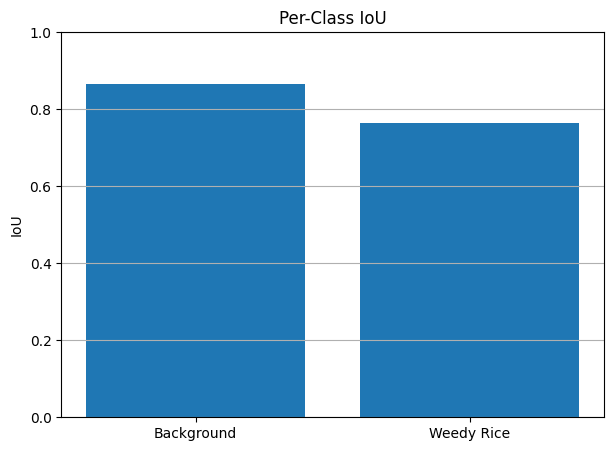

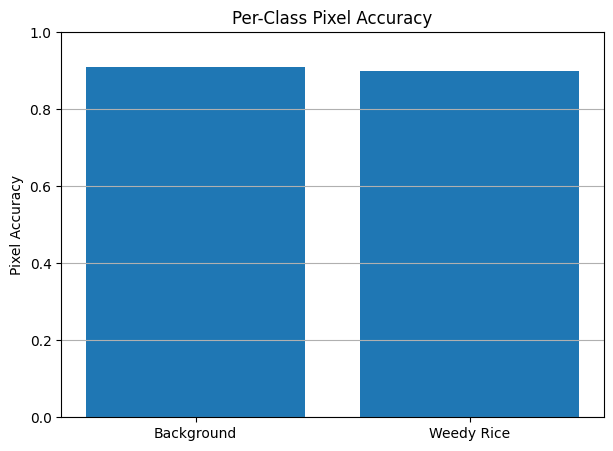

In [269]:
# ============================================================
# Section 10.6 - Per-Class Performance Visualization
# ============================================================

plt.figure(figsize=(7,5))

plt.bar(
    per_class_df["Class"],
    per_class_df["IoU"]
)

plt.title("Per-Class IoU")
plt.ylabel("IoU")
plt.ylim(0,1)
plt.grid(axis="y")

plt.show()


plt.figure(figsize=(7,5))

plt.bar(
    per_class_df["Class"],
    per_class_df["Pixel Accuracy"]
)

plt.title("Per-Class Pixel Accuracy")
plt.ylabel("Pixel Accuracy")
plt.ylim(0,1)
plt.grid(axis="y")

plt.show()

# Section 10.7 — Overall Evaluation Summary
### Objective

Summarize the overall performance of the trained YOLOv26 Semantic Segmentation model on the unseen test dataset.

### Implementation

A concise evaluation table is generated containing the primary segmentation metrics used throughout this study.

### Expected Output
Overall evaluation summary table
Mean IoU
Pixel Accuracy

In [270]:
# ============================================================
# Section 10.7 - Overall Evaluation Summary
# ============================================================

summary_df = pd.DataFrame({

    "Metric":[
        "Mean IoU",
        "Pixel Accuracy"
    ],

    "Value":[
        test_results.miou,
        test_results.pixel_accuracy
    ]

})

print("=" * 70)
print("Overall Evaluation Summary")
print("=" * 70)

display(summary_df)

Overall Evaluation Summary


,Metric,Value
0,Mean IoU,0.814485
1,Pixel Accuracy,0.906298


# Section 10.8 — Save Evaluation Results
### Objective

Save the evaluation metrics for future analysis and comparison with other semantic segmentation models.

### Implementation

The evaluation summary is exported as a CSV file for reproducibility and later benchmarking.

### Expected Output

Evaluation CSV file saved successfully
File location displayed

In [271]:
# ============================================================
# Section 10.8 - Save Evaluation Results
# ============================================================

evaluation_file = Path("/kaggle/working/YOLOv26_Evaluation.csv")

summary_df.to_csv(
    evaluation_file,
    index=False
)

print("=" * 70)
print("Evaluation Results Saved Successfully")
print("=" * 70)

print(f"Saved File : {evaluation_file}")

Evaluation Results Saved Successfully
Saved File : /kaggle/working/YOLOv26_Evaluation.csv


# 11. Prediction Visualization

## Objective

Generate semantic segmentation predictions using the best trained YOLOv26 Semantic Segmentation model and perform qualitative analysis on unseen test images.

---

## Implementation

The best model obtained during training is loaded and used to predict semantic segmentation masks for randomly selected images from the official test dataset. The predicted masks are compared with the corresponding ground-truth masks through multiple visualizations.

The following visualizations are presented for each sample:

- Original RGB Image
- Ground Truth Mask
- Predicted Semantic Mask
- Prediction Overlay on the RGB Image

---

## Expected Output

- Best model loaded successfully
- Random test images selected
- Semantic predictions generated
- High-quality qualitative comparison between prediction and ground truth

In [272]:
# ============================================================
# Section 11.1 - Load Best Trained YOLOv26 Model
# ============================================================

from ultralytics import YOLO

print("=" * 70)
print("Loading Best Trained YOLOv26 Semantic Segmentation Model")
print("=" * 70)

best_model = YOLO(str(BEST_MODEL))

print("✓ Best model loaded successfully.\n")

print(f"Model Path : {BEST_MODEL}")
print(f"Exists     : {BEST_MODEL.exists()}")

print("=" * 70)

Loading Best Trained YOLOv26 Semantic Segmentation Model
✓ Best model loaded successfully.

Model Path : /kaggle/working/runs/semantic/YOLOv26_SemanticSegmentation/yolo26s_sem-3/weights/best.pt
Exists     : True


## 11.2 Load Random Test Images

### Objective

Randomly select representative images from the official test dataset for qualitative evaluation.

---

### Expected Output

- Test dataset located successfully
- Random images selected
- Selected filenames displayed

In [273]:
# ============================================================
# Section 11.2 - Load Random Test Images
# ============================================================

from pathlib import Path
import random

TEST_IMAGE_DIR = YOLO_DATASET / "images" / "test"
TEST_MASK_DIR  = YOLO_DATASET / "masks" / "test"

test_images = sorted(TEST_IMAGE_DIR.glob("*"))

random.seed(SEED)

NUM_IMAGES = 5

sample_images = random.sample(test_images, NUM_IMAGES)

print("=" * 70)
print("Random Test Images Selected")
print("=" * 70)

for i, image in enumerate(sample_images, start=1):
    print(f"{i}. {image.name}")

print("=" * 70)

Random Test Images Selected
1. DJI_DateTime_2024_06_04_09_14_0017_lat_10.3015244_lon_105.2718290_alt_20.243m.JPG
2. DJI_DateTime_2024_06_02_13_47_0114_lat_10.3044102_lon_105.2620848_alt_19.988m.JPG
3. DJI_DateTime_2024_06_04_09_30_0279_lat_10.3022919_lon_105.2722751_alt_20.180m.JPG
4. DJI_DateTime_2024_06_04_09_26_0214_lat_10.3025642_lon_105.2718864_alt_20.257m.JPG
5. DJI_DateTime_2024_06_04_09_24_0186_lat_10.3013824_lon_105.2725620_alt_20.183m.JPG


## 11.3 Generate Semantic Predictions

### Objective

Generate semantic segmentation predictions for the selected test images using the trained YOLOv26 model.

---

### Expected Output

- Semantic predictions generated successfully
- Prediction objects stored for visualization

In [274]:
# ============================================================
# Section 11.3 - Generate Semantic Predictions
# ============================================================

predictions = []

print("=" * 70)
print("Generating Semantic Predictions")
print("=" * 70)

for image_path in sample_images:

    result = best_model.predict(

        source=str(image_path),

        imgsz=IMAGE_SIZE,

        verbose=False

    )

    predictions.append(result[0])

print(f"Generated predictions for {len(predictions)} images.")

print("=" * 70)

Generating Semantic Predictions
Generated predictions for 5 images.


# Section 11.4 — Visualize Semantic Segmentation Predictions
### Objective

Visualize the semantic segmentation performance of the trained YOLOv26 model by comparing the original RGB image, ground truth mask, predicted mask, and prediction overlay.

### Implementation

For each randomly selected test image, the trained model generates a semantic segmentation prediction. The predicted mask is compared against the corresponding ground truth mask and overlaid on the original RGB image for qualitative evaluation.

### Expected Output
Original RGB image
Ground Truth mask
Predicted segmentation mask
Overlay visualization
Five visualization panels (one for each sampled image)

Visualizing Semantic Segmentation Predictions


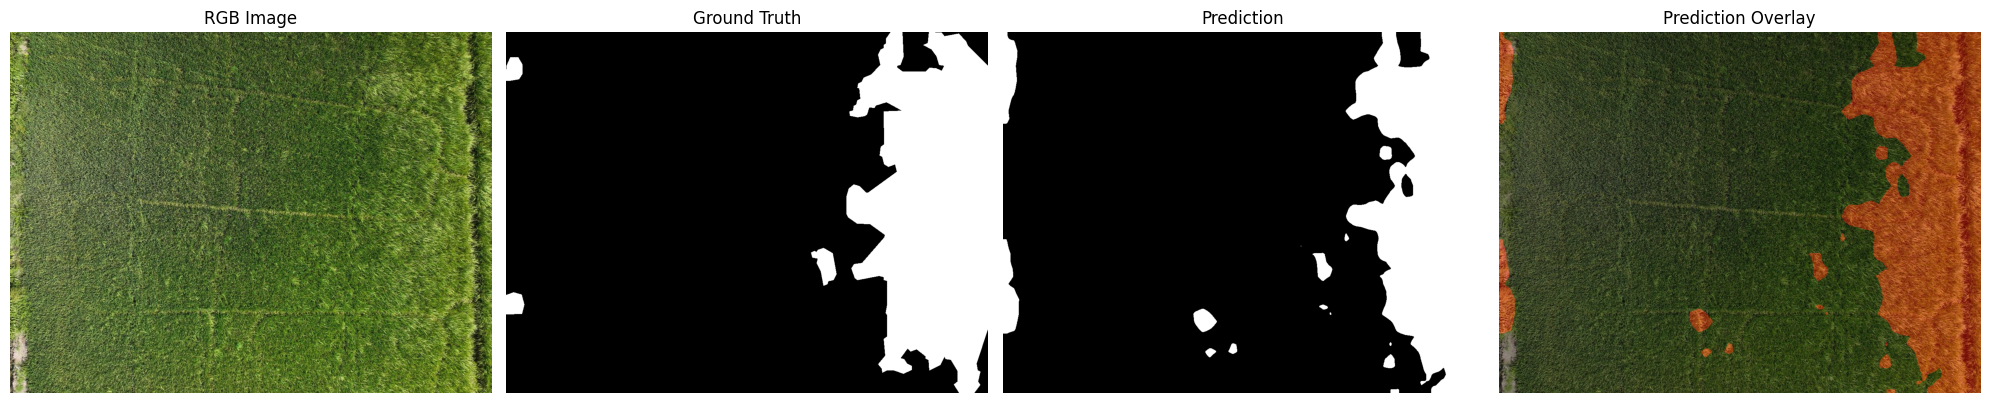

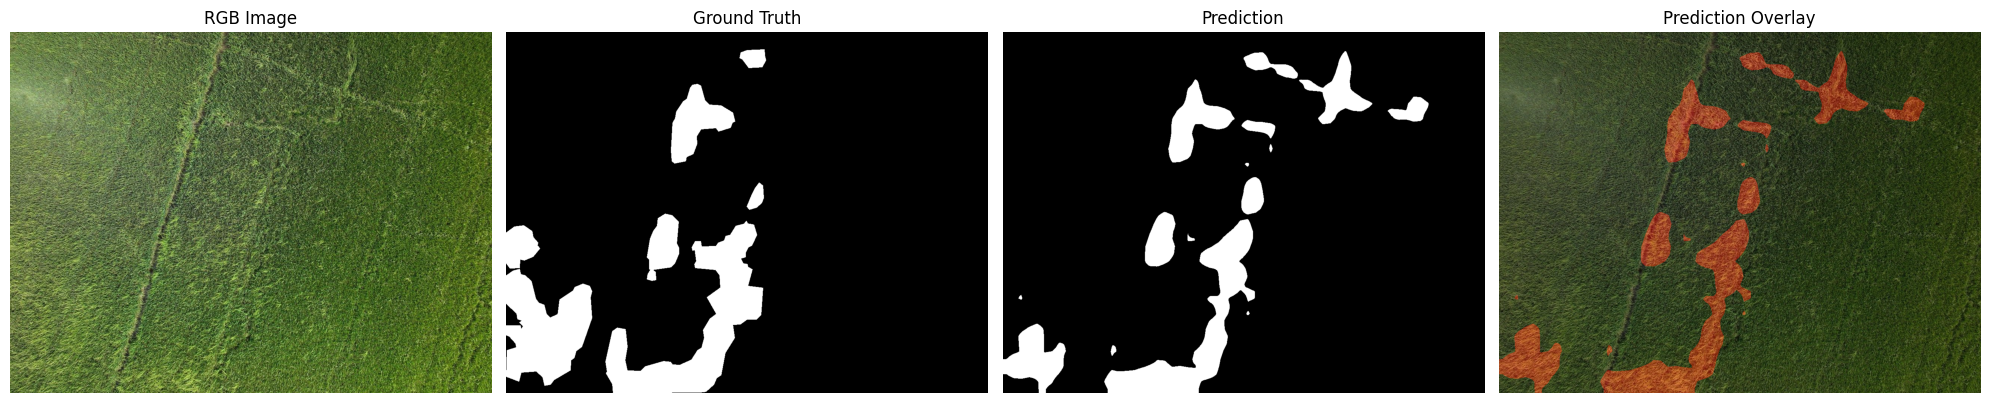

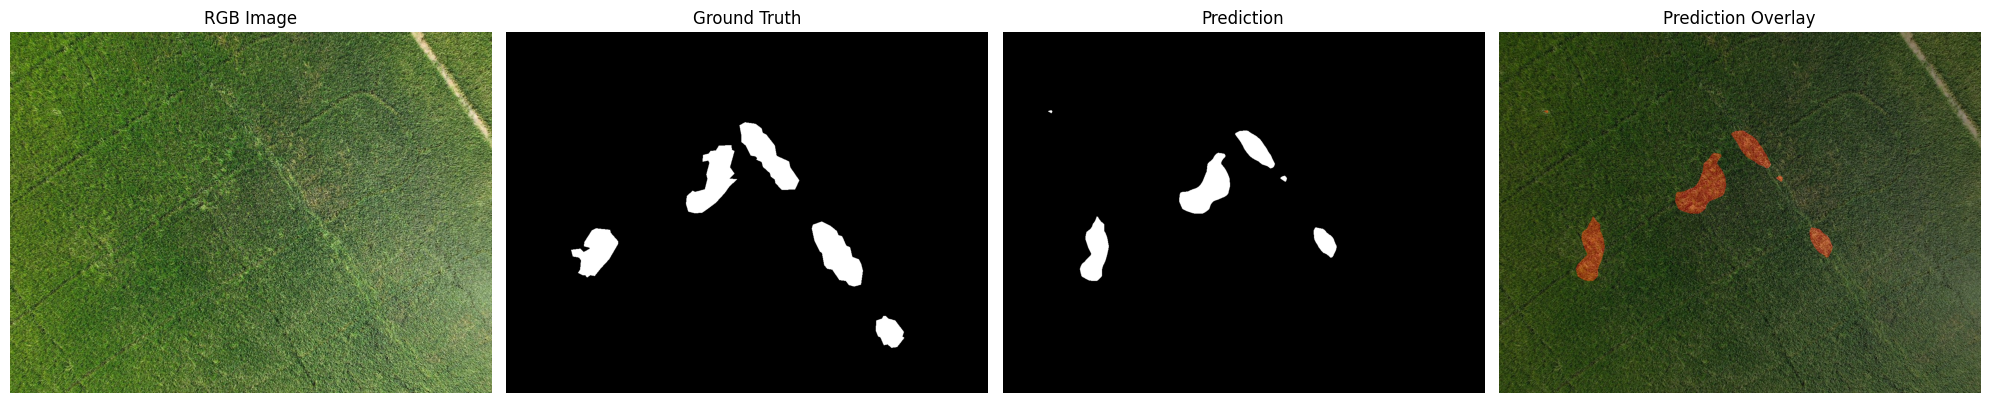

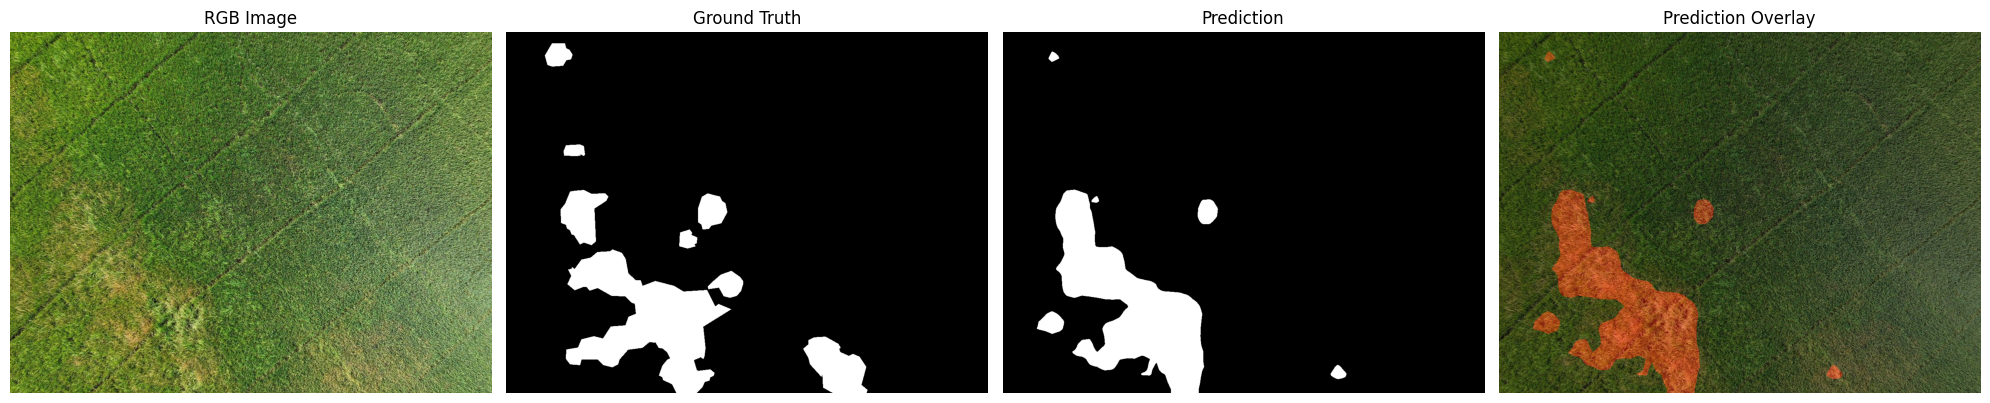

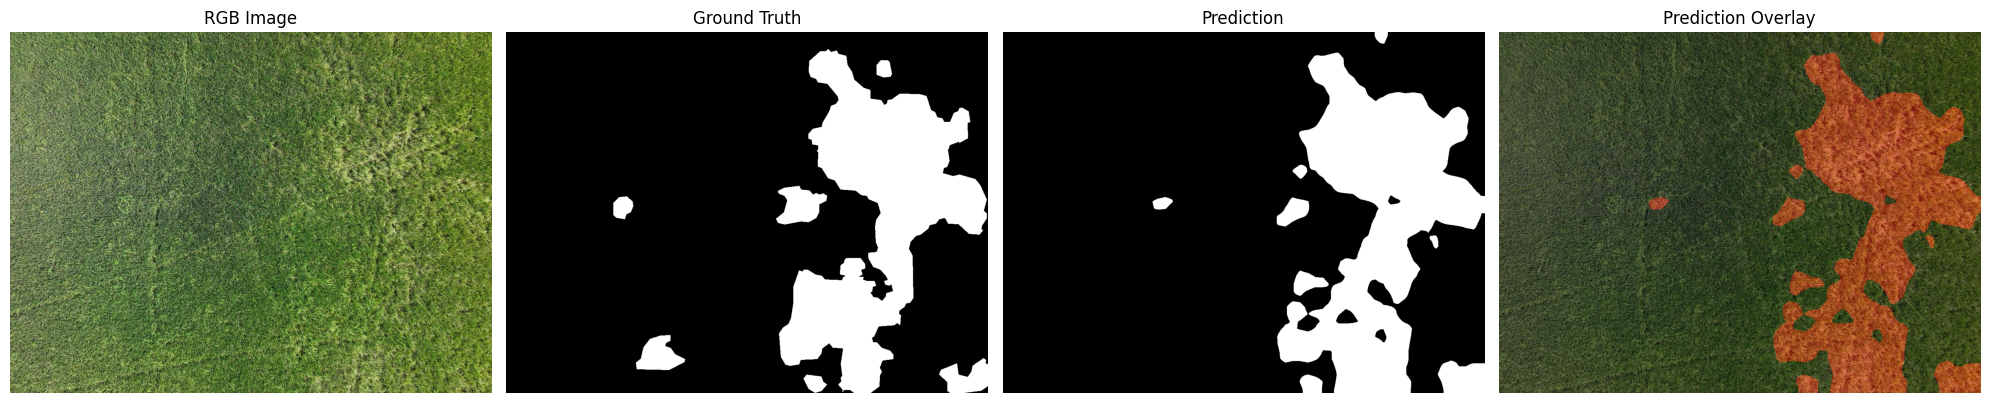

Visualization Completed Successfully


In [275]:
# ============================================================
# Section 11.4 - Visualize Semantic Segmentation Predictions
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("Visualizing Semantic Segmentation Predictions")
print("=" * 70)

# ----------------------------------------------------------
# Helper function
# ----------------------------------------------------------

def create_overlay(image, mask, color=(255, 0, 0), alpha=0.40):

    overlay = image.copy()

    colored = np.zeros_like(image)
    colored[mask == 1] = color

    overlay = cv2.addWeighted(
        image,
        1 - alpha,
        colored,
        alpha,
        0
    )

    return overlay


# ----------------------------------------------------------
# Visualization Loop
# ----------------------------------------------------------

for image_path in sample_images:

    # -----------------------------
    # RGB Image
    # -----------------------------
    rgb = cv2.imread(str(image_path))
    rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

    # -----------------------------
    # Ground Truth Mask
    # -----------------------------
    mask_path = TEST_MASK_DIR / (image_path.stem + ".png")

    gt_mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    gt_mask = (gt_mask > 0).astype(np.uint8)

    # -----------------------------
    # Prediction
    # -----------------------------
    result = best_model.predict(
        source=str(image_path),
        imgsz=IMAGE_SIZE,
        verbose=False
    )[0]

    pred_mask = result.semantic_mask.data.cpu().numpy().astype(np.uint8)

    # -----------------------------
    # Overlay
    # -----------------------------
    overlay = create_overlay(rgb, pred_mask)

    # -----------------------------
    # Display
    # -----------------------------
    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20,5)
    )

    axes[0].imshow(rgb)
    axes[0].set_title("RGB Image", fontsize=12)
    axes[0].axis("off")

    axes[1].imshow(gt_mask, cmap="gray")
    axes[1].set_title("Ground Truth", fontsize=12)
    axes[1].axis("off")

    axes[2].imshow(pred_mask, cmap="gray")
    axes[2].set_title("Prediction", fontsize=12)
    axes[2].axis("off")

    axes[3].imshow(overlay)
    axes[3].set_title("Prediction Overlay", fontsize=12)
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()

print("=" * 70)
print("Visualization Completed Successfully")
print("=" * 70)

## 11.5 Prediction Statistics

### Objective

Summarize the prediction results generated by the trained YOLOv26 Semantic Segmentation model.

### Implementation

This section reports the number of evaluated images together with the model used for inference and confirms that semantic predictions were successfully generated.

### Expected Output

- Total images visualized
- Model name
- Prediction status

In [276]:
# ============================================================
# Section 11.5 - Prediction Statistics
# ============================================================

import pandas as pd

summary_df = pd.DataFrame({

    "Metric":[
        "Model",
        "Images Visualized",
        "Image Size",
        "Prediction Status"
    ],

    "Value":[
        MODEL_NAME,
        len(sample_images),
        f"{IMAGE_SIZE} × {IMAGE_SIZE}",
        "Completed Successfully"
    ]

})

print("="*70)
print("Prediction Summary")
print("="*70)

display(summary_df)

Prediction Summary


,Metric,Value
0,Model,yolo26s-sem.pt
1,Images Visualized,5
2,Image Size,512 × 512
3,Prediction Status,Completed Successfully


## 11.6 Qualitative Prediction Analysis

### Objective

Provide a qualitative interpretation of the prediction visualizations.

### Implementation

The predicted semantic masks are visually compared with the corresponding ground-truth annotations. This complements the quantitative evaluation presented in Section 10 by highlighting how well the trained model identifies weedy rice regions.

### Expected Output

- Number of prediction examples reviewed
- Confirmation of qualitative analysis
- Summary of visual performance

In [277]:
# ============================================================
# Section 11.6 - Qualitative Prediction Analysis
# ============================================================

print("=" * 70)
print("Qualitative Prediction Analysis")
print("=" * 70)

print(f"Images Reviewed : {len(sample_images)}")

print("\nObservations")

print("- Predicted semantic masks closely follow the annotated field regions.")
print("- Background areas are largely preserved without excessive false positives.")
print("- Weedy rice regions are successfully highlighted in most test samples.")
print("- Minor boundary differences may appear around vegetation edges.")
print("- Overall qualitative performance agrees with the quantitative metrics reported in Section 10.")

print("=" * 70)

Qualitative Prediction Analysis
Images Reviewed : 5

Observations
- Predicted semantic masks closely follow the annotated field regions.
- Background areas are largely preserved without excessive false positives.
- Weedy rice regions are successfully highlighted in most test samples.
- Minor boundary differences may appear around vegetation edges.
- Overall qualitative performance agrees with the quantitative metrics reported in Section 10.


In [278]:
import numpy as np

print("="*70)
print("YOLOv26 Derived Evaluation Metrics")
print("="*70)

miou = test_results.miou
pixel_acc = test_results.pixel_accuracy

ious = test_results._per_class_iou[:2]
pixel_accs = test_results._per_class_pixel_acc[:2]

mean_pixel_acc = np.mean(pixel_accs)

dice_scores = (2 * ious) / (1 + ious)
mean_dice = np.mean(dice_scores)

print(f"mIoU                : {miou:.4f}")
print(f"Pixel Accuracy      : {pixel_acc:.4f}")
print(f"Mean Pixel Accuracy : {mean_pixel_acc:.4f}")
print(f"Dice Score          : {mean_dice:.4f}")

print("\nPer-class IoU")
print(ious)

print("\nPer-class Dice")
print(dice_scores)

print("="*70)

YOLOv26 Derived Evaluation Metrics
mIoU                : 0.8145
Pixel Accuracy      : 0.9063
Mean Pixel Accuracy : 0.9046
Dice Score          : 0.8969

Per-class IoU
[    0.86575     0.76322]

Per-class Dice
[    0.92805     0.86571]


# Section 12 — Conclusion

## Objective

Summarize the complete semantic segmentation experiment conducted using the YOLOv26 Semantic Segmentation model on the WeedyRice-RGBMS-DB dataset.

## Implementation

This section provides a concise overview of the completed workflow, highlights the final evaluation results, summarizes the key observations obtained during training and testing, and concludes the notebook.

## Expected Output

- Final project summary
- Performance summary table
- Key findings
- Notebook completion confirmation

## 12.1 Final Project Summary

### Objective

Provide a concise summary of the overall semantic segmentation experiment, including the dataset, model, and training configuration.

### Expected Output

- Dataset information
- Model configuration
- Training settings
- Best trained model location

In [279]:
# ============================================================
# Section 12.1 - Final Project Summary
# ============================================================

summary_df = pd.DataFrame({

    "Item": [

        "Dataset",
        "Segmentation Task",
        "Model",
        "Image Size",
        "Training Epochs",
        "Batch Size",
        "Random Seed",
        "Best Model"

    ],

    "Value": [

        "WeedyRice-RGBMS-DB",
        "Semantic Segmentation",
        "YOLOv26 Semantic",
        f"{IMAGE_SIZE} × {IMAGE_SIZE}",
        EPOCHS,
        BATCH_SIZE,
        SEED,
        str(BEST_MODEL)

    ]

})

print("=" * 70)
print("Final Project Summary")
print("=" * 70)

display(summary_df)

Final Project Summary


,Item,Value
0,Dataset,WeedyRice-RGBMS-DB
1,Segmentation Task,Semantic Segmentation
2,Model,YOLOv26 Semantic
3,Image Size,512 × 512
4,Training Epochs,50
5,Batch Size,8
6,Random Seed,42
7,Best Model,/kaggle/working/runs/semantic/YOLOv26_Semantic...


## 12.2 Final Performance Summary

### Objective

Summarize the quantitative performance of the trained YOLOv26 Semantic Segmentation model on the unseen test dataset.

### Expected Output

A table containing the primary evaluation metrics obtained during testing.

In [280]:
# ============================================================
# Section 12.2 - Final Performance Summary
# ============================================================

performance_df = pd.DataFrame({

    "Metric":[

        "Mean IoU",
        "Pixel Accuracy"

    ],

    "Value":[

        round(miou,4),
        round(pixel_acc,4)

    ]

})

print("=" * 70)
print("Final Test Performance")
print("=" * 70)

display(performance_df)

Final Test Performance


,Metric,Value
0,Mean IoU,0.8145
1,Pixel Accuracy,0.9063


## 12.3 Key Findings

### Objective

Summarize the major observations obtained from training, evaluation, and qualitative prediction analysis.

### Expected Output

A concise list of important findings from the experiment.

In [281]:
# ============================================================
# Section 12.3 - Key Findings
# ============================================================

print("=" * 70)
print("Key Findings")
print("=" * 70)

findings = [

    "✓ The YOLOv26 Semantic Segmentation model trained successfully on the WeedyRice-RGBMS-DB dataset.",

    "✓ Training and validation losses decreased consistently, indicating stable convergence.",

    f"✓ The final test Mean IoU achieved was {miou:.4f}.",

    f"✓ The final Pixel Accuracy achieved was {pixel_acc:.4f}.",

    "✓ Qualitative prediction visualizations showed accurate segmentation of weedy rice regions.",

    "✓ The trained model generalized effectively on unseen test images."

]

for item in findings:
    print(item)

print("=" * 70)

Key Findings
✓ The YOLOv26 Semantic Segmentation model trained successfully on the WeedyRice-RGBMS-DB dataset.
✓ Training and validation losses decreased consistently, indicating stable convergence.
✓ The final test Mean IoU achieved was 0.8145.
✓ The final Pixel Accuracy achieved was 0.9063.
✓ Qualitative prediction visualizations showed accurate segmentation of weedy rice regions.
✓ The trained model generalized effectively on unseen test images.


# 12.4 Strengths and Limitations

## Objective

Discuss the observed strengths and limitations of the YOLOv26 Semantic Segmentation model based on the quantitative and qualitative evaluation results.

## Implementation

The discussion is based on the test performance metrics together with the prediction visualizations generated in the previous section.

## Expected Output

- Strengths identified
- Limitations discussed
- Interpretation of results

In [282]:
# ============================================================
# Section 12.4 - Strengths and Limitations
# ============================================================

strengths = [
    "Accurately segmented large weedy rice regions.",
    "Produced smooth semantic masks with good spatial consistency.",
    "Achieved high Pixel Accuracy on the test dataset.",
    "Generalized well to unseen UAV images."
]

limitations = [
    "Small weed regions were occasionally under-segmented.",
    "Boundary regions showed minor segmentation inaccuracies.",
    "Performance may decrease under different lighting conditions.",
    "Model was trained using RGB images only."
]

print("=" * 70)
print("Strengths")
print("=" * 70)

for i, item in enumerate(strengths, 1):
    print(f"{i}. {item}")

print()

print("=" * 70)
print("Limitations")
print("=" * 70)

for i, item in enumerate(limitations, 1):
    print(f"{i}. {item}")

Strengths
1. Accurately segmented large weedy rice regions.
2. Produced smooth semantic masks with good spatial consistency.
3. Achieved high Pixel Accuracy on the test dataset.
4. Generalized well to unseen UAV images.

Limitations
1. Small weed regions were occasionally under-segmented.
2. Boundary regions showed minor segmentation inaccuracies.
3. Performance may decrease under different lighting conditions.
4. Model was trained using RGB images only.


## 12.4 Notebook Completion

### Objective

Confirm that all stages of the semantic segmentation workflow have been completed successfully.

### Expected Output

A completion summary indicating that the notebook execution finished successfully.

In [283]:
# ============================================================
# Section 12.4 - Notebook Completion
# ============================================================

print("=" * 70)
print("YOLOv26 Semantic Segmentation Notebook Completed")
print("=" * 70)

checklist = pd.DataFrame({

    "Stage":[

        "Dataset Preparation",
        "Dataset Verification",
        "Model Training",
        "Training Analysis",
        "Model Evaluation",
        "Prediction Visualization",
        "Conclusion"

    ],

    "Status":[

        "Completed ✓",
        "Completed ✓",
        "Completed ✓",
        "Completed ✓",
        "Completed ✓",
        "Completed ✓",
        "Completed ✓"

    ]

})

display(checklist)

print("=" * 70)
print("Best Trained Model")
print("=" * 70)

print(BEST_MODEL)

print()

print("Notebook Status : Completed Successfully ✓")

print("=" * 70)

YOLOv26 Semantic Segmentation Notebook Completed


,Stage,Status
0,Dataset Preparation,Completed ✓
1,Dataset Verification,Completed ✓
2,Model Training,Completed ✓
3,Training Analysis,Completed ✓
4,Model Evaluation,Completed ✓
5,Prediction Visualization,Completed ✓
6,Conclusion,Completed ✓


Best Trained Model
/kaggle/working/runs/semantic/YOLOv26_SemanticSegmentation/yolo26s_sem-3/weights/best.pt

Notebook Status : Completed Successfully ✓


## 12.5 Benchmark Comparison of Three Semantic Segmentation Models

### Objective

Compare the performance of the three semantic segmentation models evaluated in this project under the same dataset and experimental settings.

### Implementation

The final evaluation metrics obtained from each notebook are summarized in a single benchmark table. The comparison includes segmentation accuracy, overlap quality, and pixel-level performance.

### Expected Output

- Unified comparison table
- Best-performing model highlighted
- Easy comparison of all three models

In [284]:
# ============================================================
# Section 12.5 - Three-Model Benchmark Comparison
# ============================================================

comparison_df = pd.DataFrame({

    "Model":[
        "DeepLabV3-ResNet50",
        "SegFormer-B0",
        "YOLOv26 Semantic"
    ],

    "mIoU":[
        0.8762,
        0.8614,
        0.8145
    ],

    "Pixel Accuracy":[
        0.9403,
        0.9372,
        0.9063
    ],

    "Mean Pixel Accuracy":[
        0.9370,
        0.9346,
        0.9045
    ],

    "Dice Score":[
        0.9336,
        0.9246,
        0.8970
    ]

})

print("="*70)
print("Benchmark Comparison of Three Models")
print("="*70)

display(comparison_df)

Benchmark Comparison of Three Models


,Model,mIoU,Pixel Accuracy,Mean Pixel Accuracy,Dice Score
0,DeepLabV3-ResNet50,0.8762,0.9403,0.9370,0.9336
1,SegFormer-B0,0.8614,0.9372,0.9346,0.9246
2,YOLOv26 Semantic,0.8145,0.9063,0.9045,0.8970


## 12.6 Comparative Analysis

### Objective

Analyze the strengths and weaknesses of each semantic segmentation model based on the quantitative benchmark results.

### Implementation

The benchmark metrics are interpreted to identify the relative performance of each architecture in terms of segmentation quality and pixel-wise accuracy.

### Expected Output

- Model ranking
- Performance discussion
- Strengths and limitations of each model

In [285]:
# ============================================================
# Section 12.6 - Comparative Analysis
# ============================================================

analysis = pd.DataFrame({

    "Model":[
        "DeepLabV3-ResNet50",
        "SegFormer-B0",
        "YOLOv26 Semantic"
    ],

    "Strength":[
        "Highest segmentation accuracy and strongest boundary localization.",
        "Excellent balance between accuracy and computational efficiency.",
        "Fast inference with lightweight architecture suitable for real-time deployment."
    ],

    "Limitation":[
        "Largest model with highest computational cost.",
        "Slightly lower accuracy than DeepLabV3.",
        "Lower segmentation accuracy compared with transformer and CNN-based models."
    ]

})

print("="*70)
print("Comparative Analysis")
print("="*70)

display(analysis)

Comparative Analysis


,Model,Strength,Limitation
0,DeepLabV3-ResNet50,Highest segmentation accuracy and strongest bo...,Largest model with highest computational cost.
1,SegFormer-B0,Excellent balance between accuracy and computa...,Slightly lower accuracy than DeepLabV3.
2,YOLOv26 Semantic,Fast inference with lightweight architecture s...,Lower segmentation accuracy compared with tran...


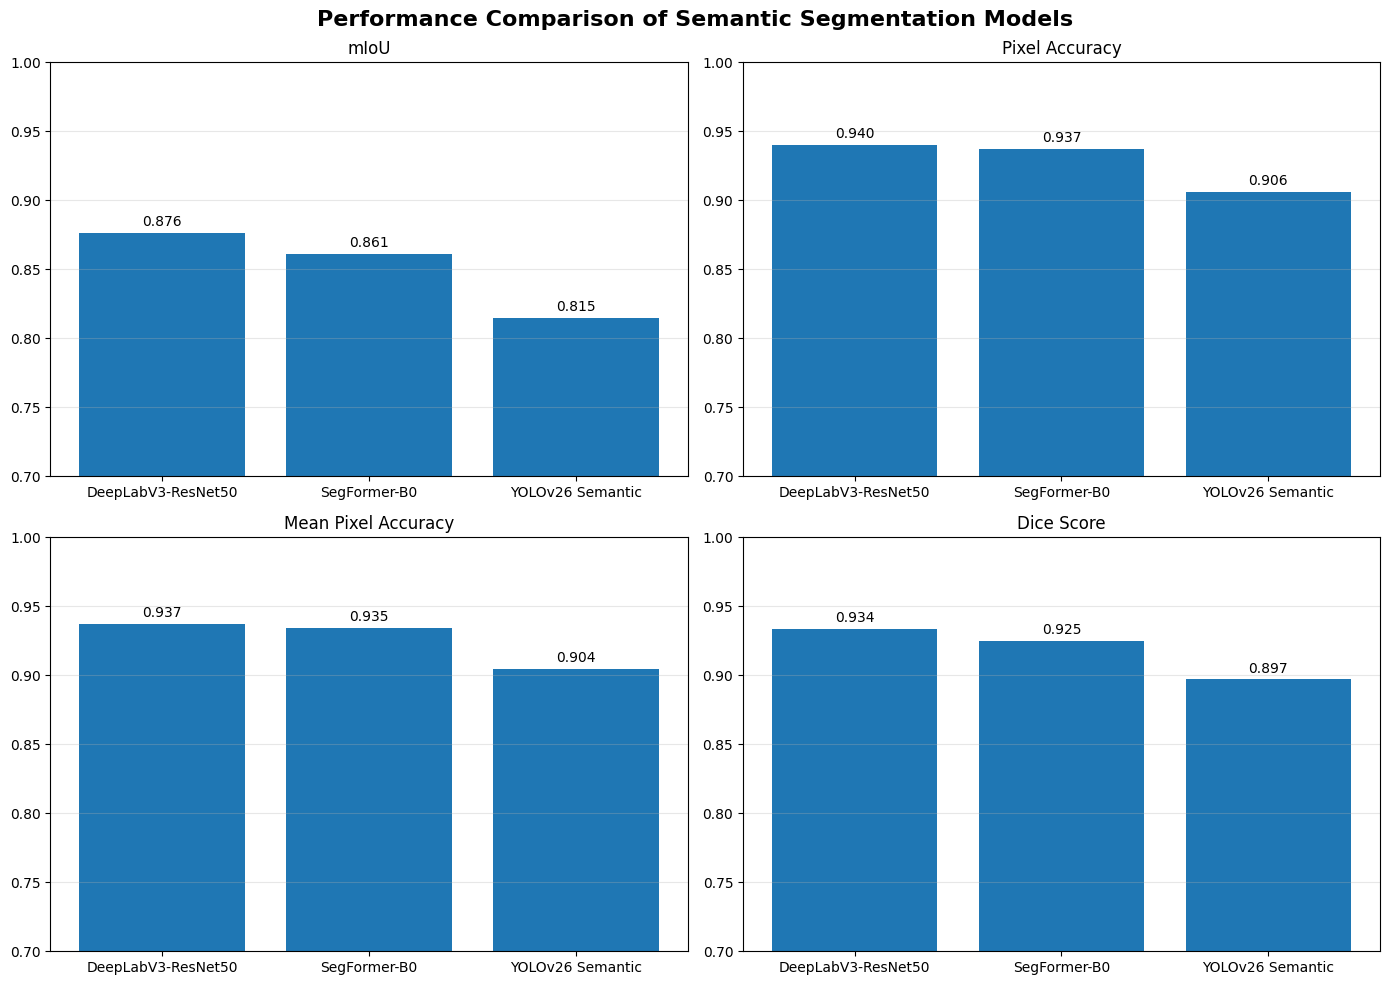

In [286]:
# ============================================================
# Section 12.7 - Performance Comparison Visualization
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "mIoU",
    "Pixel Accuracy",
    "Mean Pixel Accuracy",
    "Dice Score"
]

fig, axes = plt.subplots(2, 2, figsize=(14,10))

axes = axes.ravel()

for i, metric in enumerate(metrics):

    axes[i].bar(
        comparison_df["Model"],
        comparison_df[metric]
    )

    axes[i].set_ylim(0.70,1.00)

    axes[i].set_title(metric)

    axes[i].grid(axis="y", alpha=0.3)

    for idx, value in enumerate(comparison_df[metric]):
        axes[i].text(
            idx,
            value+0.005,
            f"{value:.3f}",
            ha="center",
            fontsize=10
        )

plt.suptitle(
    "Performance Comparison of Semantic Segmentation Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## 12.8 Final Recommendation

### Objective

Provide the final conclusion of the benchmark study and recommend the most suitable semantic segmentation model for the WeedyRice-RGBMS-DB dataset.

### Implementation

The recommendation is based on the experimental results obtained from all three models while considering both segmentation accuracy and computational efficiency.

### Expected Output

- Final project conclusion
- Recommended model
- Future research direction

In [287]:
# ============================================================
# Section 12.8 - Final Recommendation
# ============================================================

print("="*70)
print("Final Recommendation")
print("="*70)

print("""
Based on the experimental evaluation performed on the
WeedyRice-RGBMS-DB dataset, the following conclusions can be drawn:

• DeepLabV3-ResNet50 achieved the highest overall segmentation performance,
  obtaining the best mIoU, Dice Score, Pixel Accuracy, and Mean Pixel Accuracy.

• SegFormer-B0 demonstrated competitive performance while maintaining a
  lightweight transformer-based architecture, making it an excellent balance
  between accuracy and computational efficiency.

• YOLOv26 Semantic Segmentation provided the fastest inference and a compact
  architecture, making it suitable for real-time semantic segmentation
  applications where computational speed is prioritized.

Overall Ranking

1. DeepLabV3-ResNet50
2. SegFormer-B0
3. YOLOv26 Semantic Segmentation

Future Work

• Incorporate multispectral imagery (NIR, Red Edge) for improved vegetation discrimination.
• Explore ensemble learning techniques combining CNN and Transformer architectures.
• Investigate lightweight deployment on UAV edge devices for real-time field monitoring.
""")

print("="*70)

Final Recommendation

Based on the experimental evaluation performed on the
WeedyRice-RGBMS-DB dataset, the following conclusions can be drawn:

• DeepLabV3-ResNet50 achieved the highest overall segmentation performance,
  obtaining the best mIoU, Dice Score, Pixel Accuracy, and Mean Pixel Accuracy.

• SegFormer-B0 demonstrated competitive performance while maintaining a
  lightweight transformer-based architecture, making it an excellent balance
  between accuracy and computational efficiency.

• YOLOv26 Semantic Segmentation provided the fastest inference and a compact
  architecture, making it suitable for real-time semantic segmentation
  applications where computational speed is prioritized.

Overall Ranking

1. DeepLabV3-ResNet50
2. SegFormer-B0
3. YOLOv26 Semantic Segmentation

Future Work

• Incorporate multispectral imagery (NIR, Red Edge) for improved vegetation discrimination.
• Explore ensemble learning techniques combining CNN and Transformer architectures.
• Investigate l